# **Problem Statement**


---

#### **Business Context**  
Understanding customer personality and behavior is pivotal for businesses to enhance customer satisfaction and increase revenue. Segmentation based on a customer's personality, demographics, and purchasing behavior allows companies to create tailored marketing campaigns, improve customer retention, and optimize product offerings.  

A leading retail company with a rapidly growing customer base seeks to gain deeper insights into their customers' profiles. The company recognizes that understanding customer personalities, lifestyles, and purchasing habits can unlock significant opportunities for personalizing marketing strategies and creating loyalty programs. These insights can help address critical business challenges, such as improving the effectiveness of marketing campaigns, identifying high-value customer groups, and fostering long-term relationships with customers.  

With the competition intensifying in the retail space, moving away from generic strategies to more targeted and personalized approaches is essential for sustaining a competitive edge.  

---

#### **Objective**  
In an effort to optimize marketing efficiency and enhance customer experience, the company has embarked on a mission to identify distinct customer segments. By understanding the characteristics, preferences, and behaviors of each group, the company aims to:  
1. Develop personalized marketing campaigns to increase conversion rates.  
2. Create effective retention strategies for high-value customers.  
3. Optimize resource allocation, such as inventory management, pricing strategies, and store layouts.  

As a data scientist tasked with this project, your responsibility is to analyze the given customer data, apply machine learning techniques to segment the customer base, and provide actionable insights into the characteristics of each segment.  

---

#### **Data Dictionary**  
The dataset includes historical data on customer demographics, personality traits, and purchasing behaviors. Key attributes are:  

1. **Customer Information**  
   - **ID:** Unique identifier for each customer.  
   - **Year_Birth:** Customer's year of birth.  
   - **Education:** Education level of the customer.  
   - **Marital_Status:** Marital status of the customer.  
   - **Income:** Yearly household income (in dollars).  
   - **Kidhome:** Number of children in the household.  
   - **Teenhome:** Number of teenagers in the household.  
   - **Dt_Customer:** Date when the customer enrolled with the company.  
   - **Recency:** Number of days since the customer’s last purchase.  
   - **Complain:** Whether the customer complained in the last 2 years (1 for yes, 0 for no).  

2. **Spending Information (Last 2 Years)**  
   - **MntWines:** Amount spent on wine.  
   - **MntFruits:** Amount spent on fruits.  
   - **MntMeatProducts:** Amount spent on meat.  
   - **MntFishProducts:** Amount spent on fish.  
   - **MntSweetProducts:** Amount spent on sweets.  
   - **MntGoldProds:** Amount spent on gold products.  

3. **Purchase and Campaign Interaction**  
   - **NumDealsPurchases:** Number of purchases made using a discount.  
   - **AcceptedCmp1:** Response to the 1st campaign (1 for yes, 0 for no).  
   - **AcceptedCmp2:** Response to the 2nd campaign (1 for yes, 0 for no).  
   - **AcceptedCmp3:** Response to the 3rd campaign (1 for yes, 0 for no).  
   - **AcceptedCmp4:** Response to the 4th campaign (1 for yes, 0 for no).  
   - **AcceptedCmp5:** Response to the 5th campaign (1 for yes, 0 for no).  
   - **Response:** Response to the last campaign (1 for yes, 0 for no).  

4. **Shopping Behavior**  
   - **NumWebPurchases:** Number of purchases made through the company’s website.  
   - **NumCatalogPurchases:** Number of purchases made using catalogs.  
   - **NumStorePurchases:** Number of purchases made directly in stores.  
   - **NumWebVisitsMonth:** Number of visits to the company’s website in the last month.  

# **Let's start coding!**

## **Importing necessary libraries**

In [2]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)

# to scale the data using z-score
from sklearn.preprocessing import StandardScaler

# to compute distances
from scipy.spatial.distance import cdist, pdist

# to perform k-means clustering and compute silhouette scores
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# to visualize the elbow curve and silhouette scores
from yellowbrick.cluster import KElbowVisualizer, SilhouetteVisualizer

# to suppress warnings
import warnings

warnings.filterwarnings("ignore")

## **Loading the data**

In [ ]:
# uncomment and run the following line if using Google Colab
# from google.colab import drive
# drive.mount('/content/drive')

In [100]:
# loading data into a pandas dataframe
data = pd.read_csv("Customer_Personality_Segmentation.csv", sep="\t")
original_data = data.copy()

## **Data Overview**

#### **Question 1**: What are the data types of all the columns?

In [95]:
original_data.dtypes


ID                       int64
Year_Birth               int64
Education                  str
Marital_Status             str
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer                str
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPurchases          int64
NumCatalogPurchases      int64
NumStorePurchases        int64
NumWebVisitsMonth        int64
AcceptedCmp3             int64
AcceptedCmp4             int64
AcceptedCmp5             int64
AcceptedCmp1             int64
AcceptedCmp2             int64
Complain                 int64
Z_CostContact            int64
Z_Revenue                int64
Response                 int64
dtype: object

The dataset contains 29 columns. Most columns are numeric: 25 have integer data types and `Income` has a floating-point type, which allows it to represent missing values. `Education`, `Marital_Status`, and `Dt_Customer` are stored as string (text) columns.

#### **Question 2:** Check the statistical summary of the data. What is the average household income?

In [96]:
# Review descriptive statistics for numeric columns
original_data.describe().T


,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


In [97]:

# Calculate the average household income, excluding missing values
original_data["Income"].mean()

np.float64(52247.25135379061)

The statistical summary is shown above. The average household income is approximately **$52,247.25** (calculated from 2,216 non-missing income records; pandas excludes missing values when calculating the mean).

#### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method

In [98]:
missing_counts = original_data.isnull().sum()
print("Missing values per column:\n", missing_counts)

Missing values per column:
 ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64


In [102]:
income_median = original_data["Income"].median()
original_data["Income"] = original_data["Income"].fillna(income_median)

In [ ]:
#print mean again
print("Average household income:", original_data["Income"].mean())

Average household income: 52237.97544642857


##### **Observations:**

Only column Income has 24 missing values. Income varies considerably, ranging from $1,730 to $666,666, with a standard deviation of about $25,173. This suggests that extreme values may skew the mean, so the median is a better choice for imputing missing income values.

#### **Question 4**: Are there any duplicates in the data?

In [19]:
# check for duplicates in the dataset
data.duplicated().sum()

np.int64(0)

##### **Observations:**
No fully duplicated rows were found in the dataset. Therefore, no rows were removed on the basis of full-row duplication.

## **Exploratory Data Analysis**

### Univariate Analysis

#### **Question 5:** Explore all the variables and provide observations on their distributions. (histograms and boxplots)

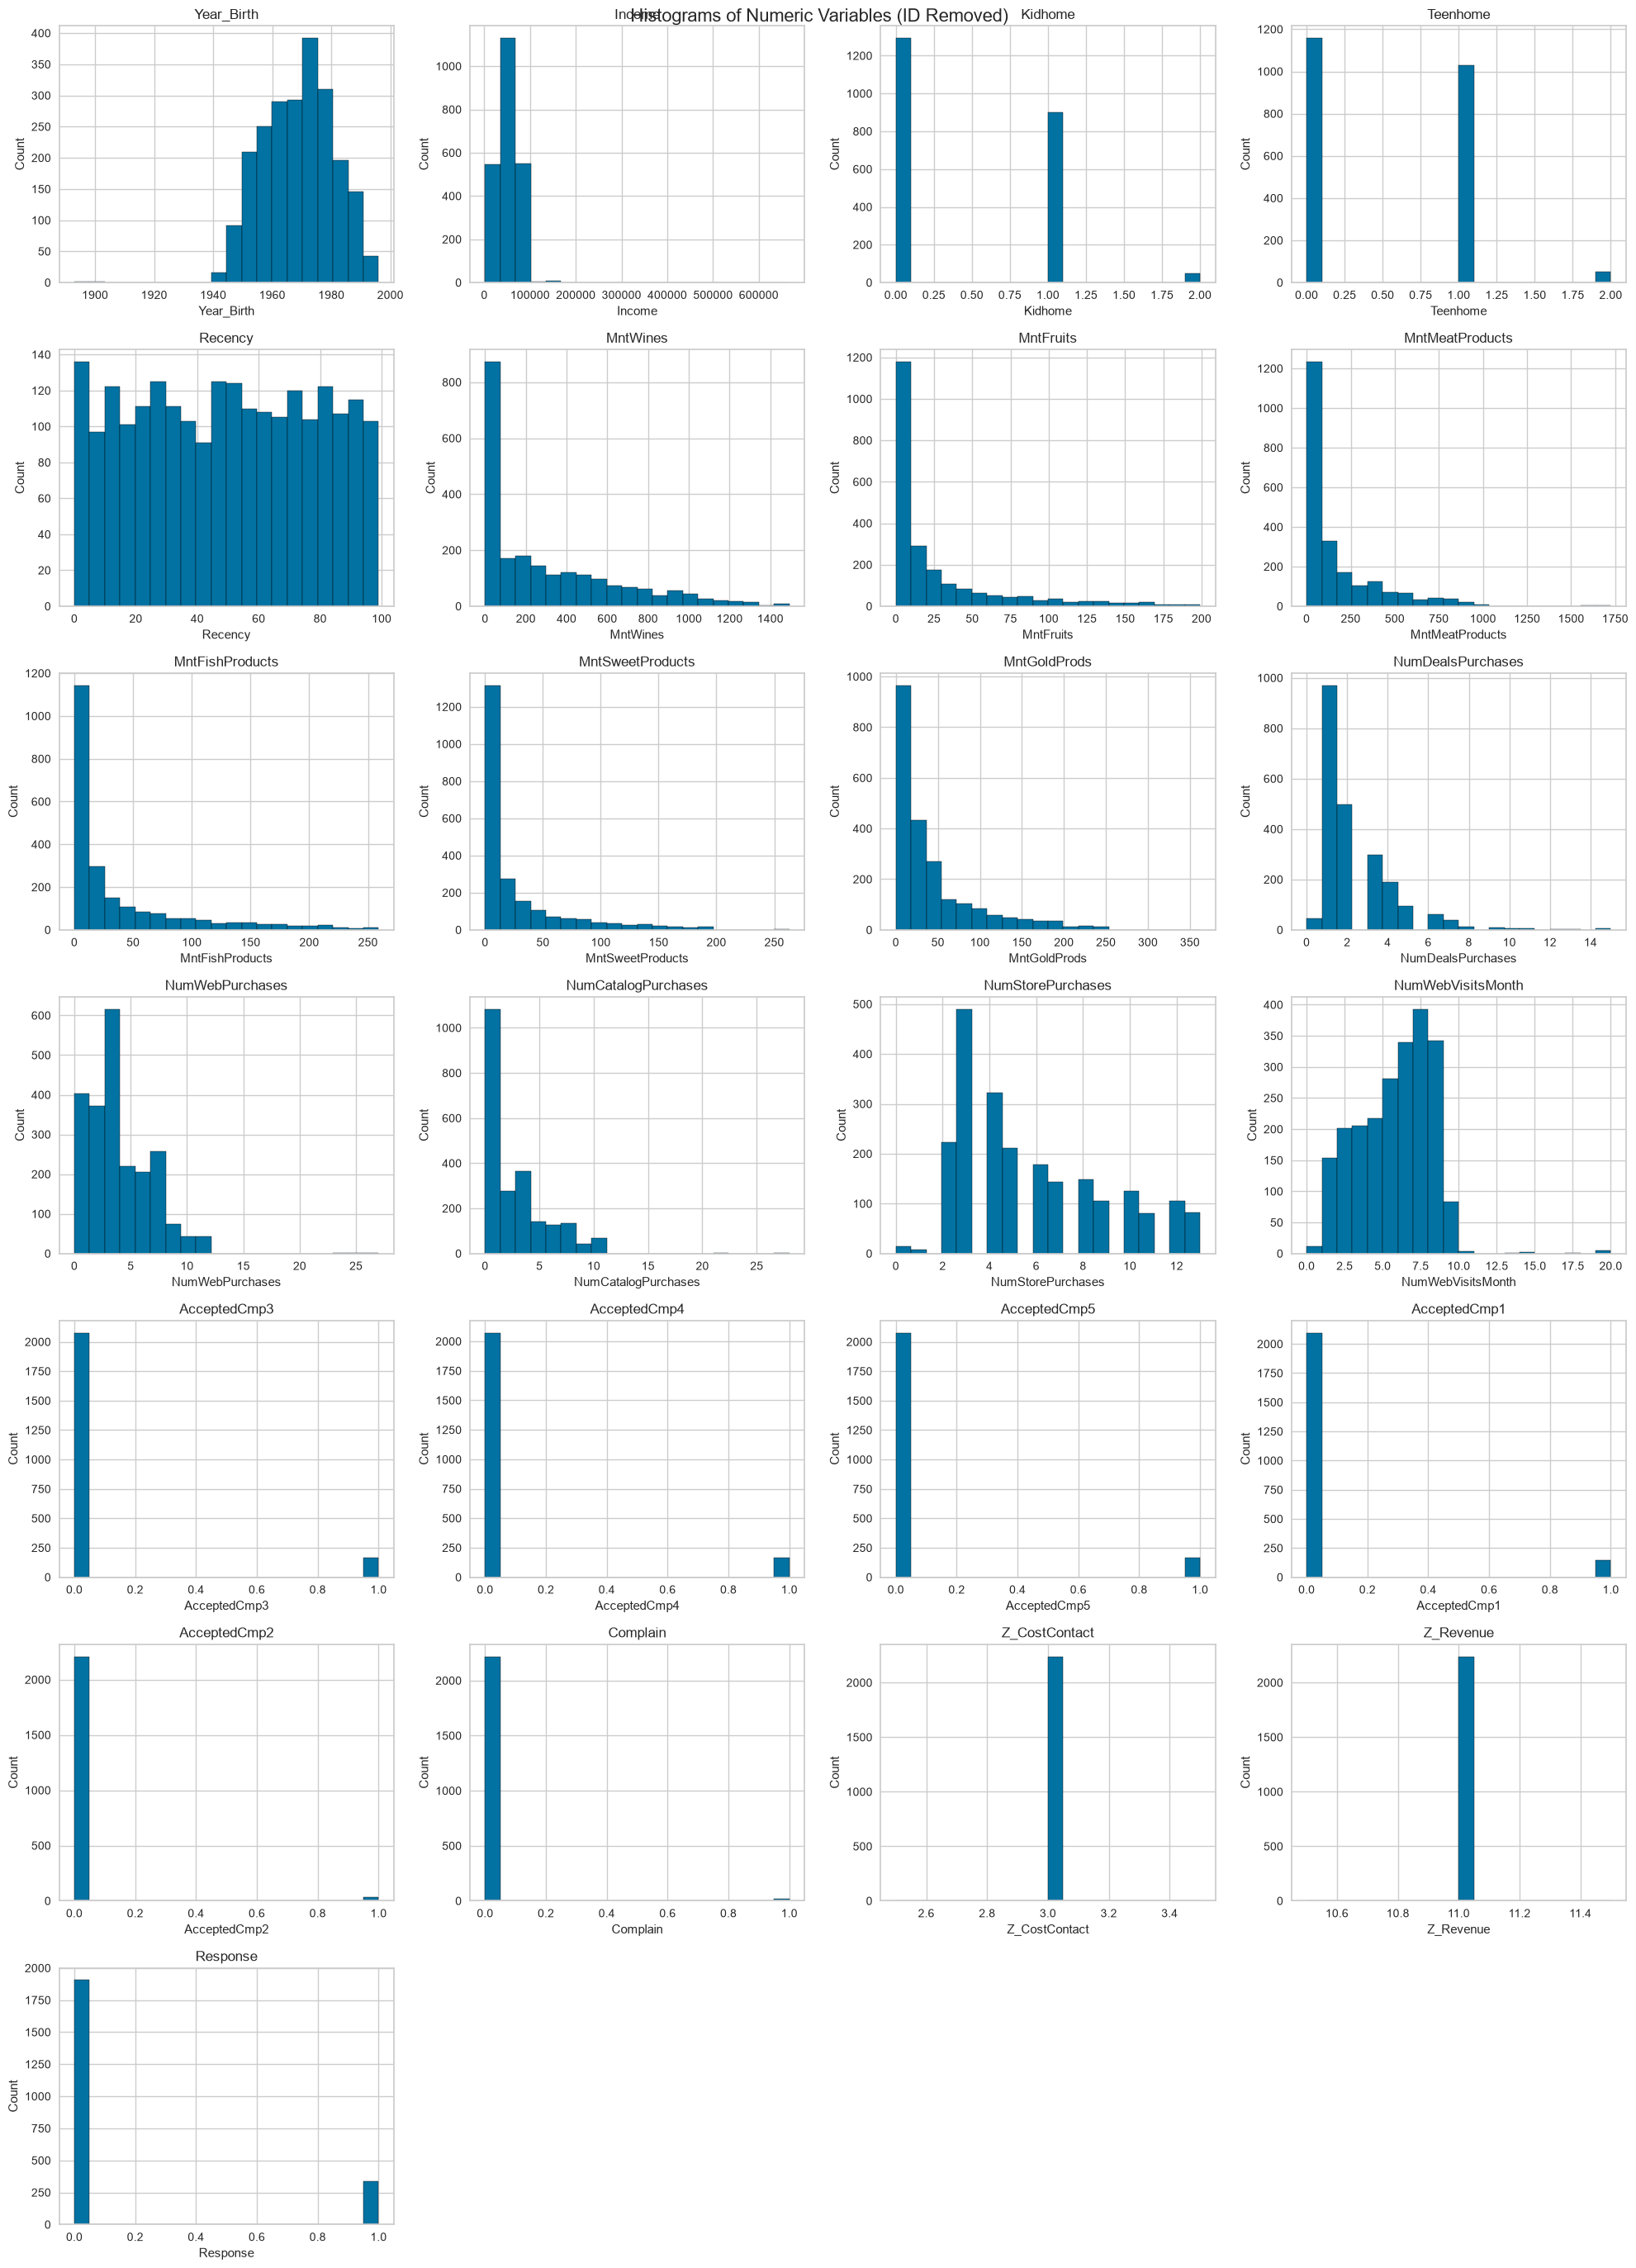

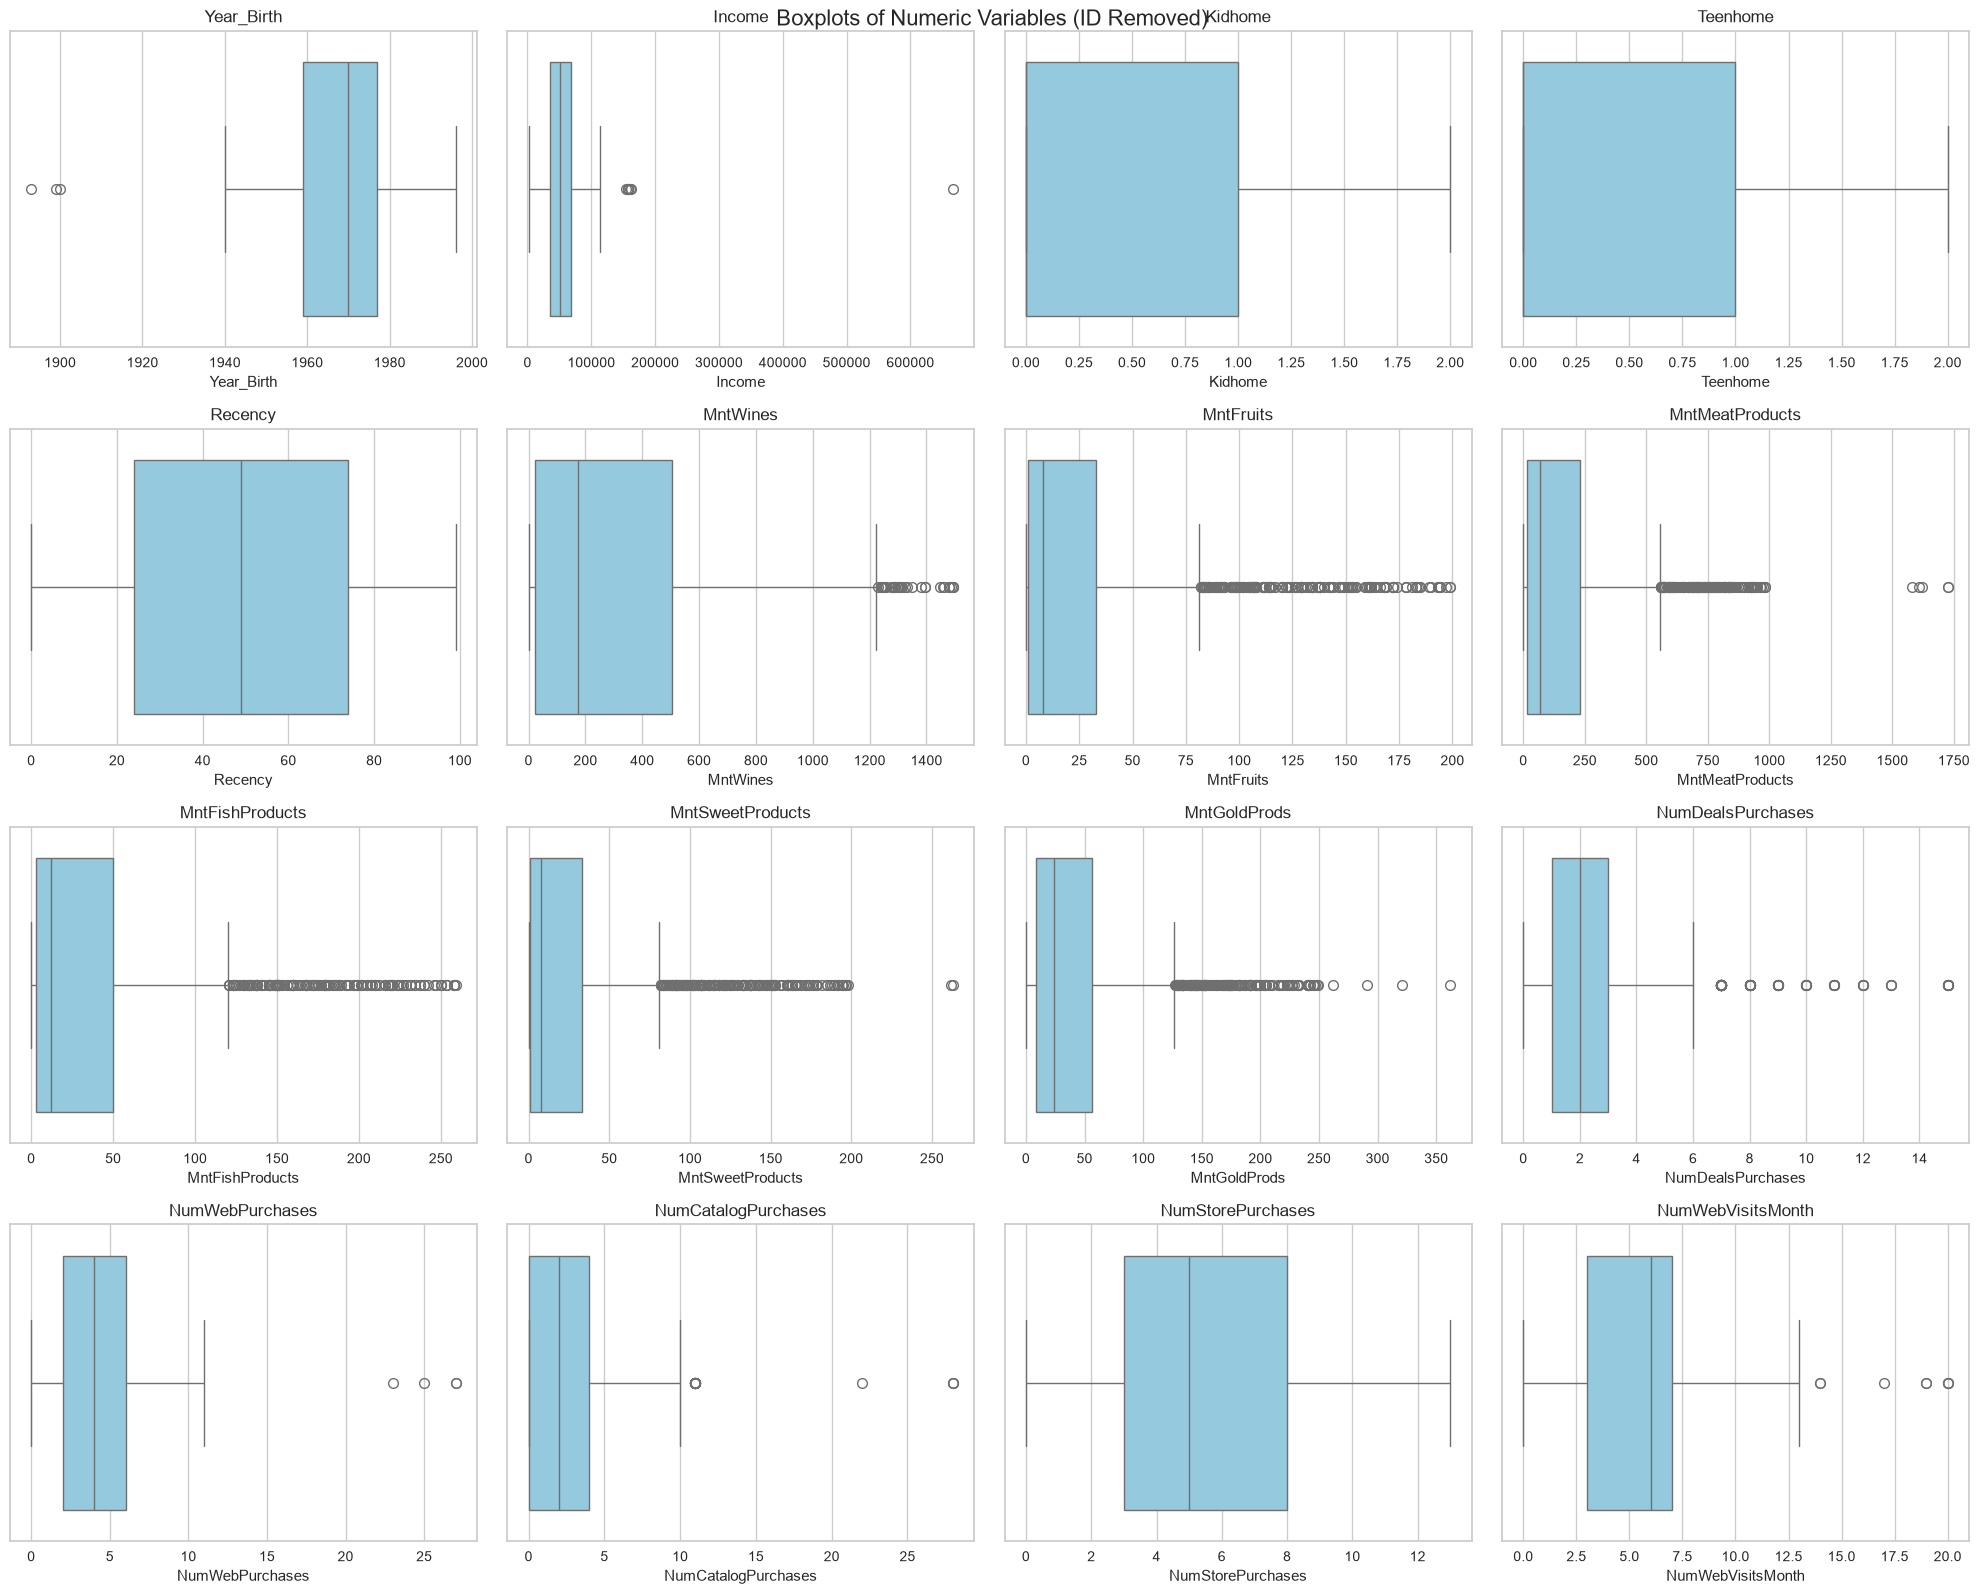

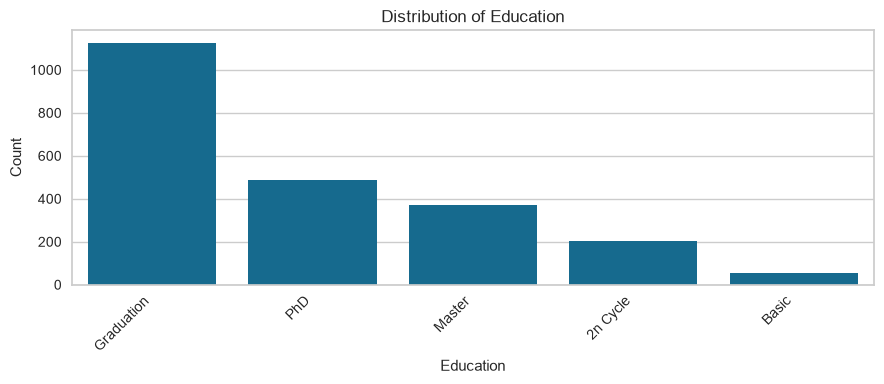

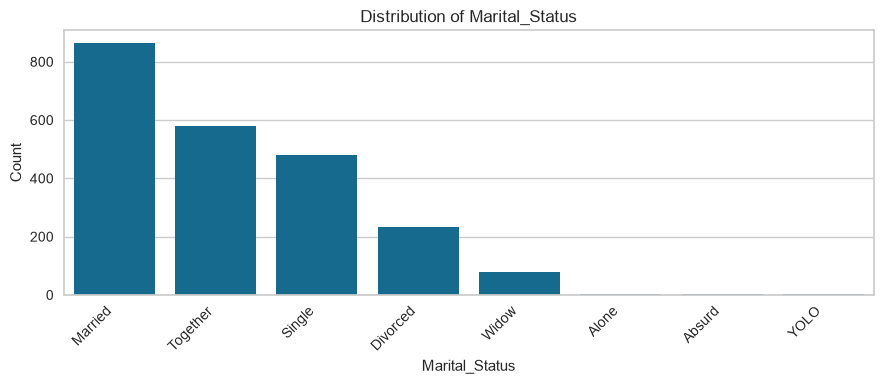

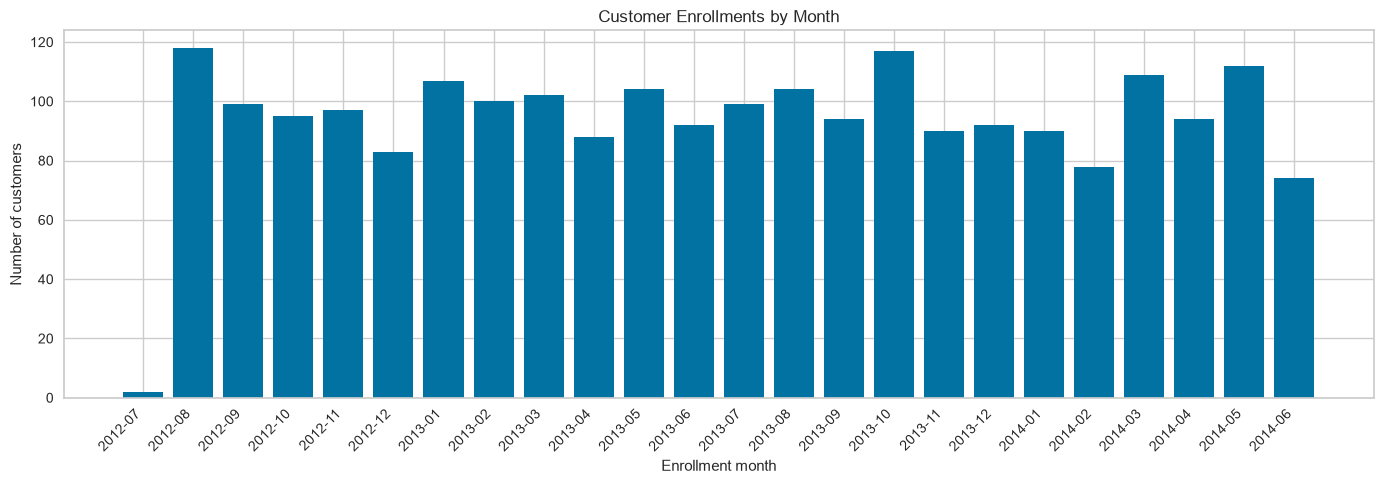

In [104]:


# Remove ID because it is only a customer identifier.
EDA_data = original_data.drop(columns=["ID"], errors="ignore").copy()

# Convert enrollment date to datetime.
EDA_data["Dt_Customer"] = pd.to_datetime(
    EDA_data["Dt_Customer"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Separate numeric and categorical variables.
numeric_cols = EDA_data.select_dtypes(include=np.number).columns.tolist()
categorical_cols = EDA_data.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Histograms for numeric variables.
ncols = 4
nrows = int(np.ceil(len(numeric_cols) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(20, 4 * nrows),
    squeeze=False
)

for column, ax in zip(numeric_cols, axes.flat):
    ax.hist(EDA_data[column].dropna(), bins=20, edgecolor="black")
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Count")

for ax in axes.flat[len(numeric_cols):]:
    ax.set_visible(False)

fig.suptitle("Histograms of Numeric Variables (ID Removed)", fontsize=16)
fig.tight_layout()
plt.show()

# Boxplots for numeric variables.
fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(20, 4 * nrows),
    squeeze=False
)

# remove columns with binary values (0 and 1) from the boxplot visualization
numeric_cols = [col for col in numeric_cols if EDA_data[col].nunique() > 2]

for column, ax in zip(numeric_cols, axes.flat):
    sns.boxplot(x=EDA_data[column], ax=ax, color="skyblue")
    ax.set_title(column)
    ax.set_xlabel(column)

for ax in axes.flat[len(numeric_cols):]:
    ax.set_visible(False)

fig.suptitle("Boxplots of Numeric Variables (ID Removed)", fontsize=16)
fig.tight_layout()
plt.show()

# Bar charts for categorical variables.
for column in categorical_cols:
    plt.figure(figsize=(9, 4))
    order = EDA_data[column].value_counts().index
    sns.countplot(data=EDA_data, x=column, order=order)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# Monthly enrollment counts for the datetime variable.
monthly_enrollments = (
    EDA_data.dropna(subset=["Dt_Customer"])
        .assign(EnrollmentMonth=lambda df: df["Dt_Customer"].dt.to_period("M"))
        ["EnrollmentMonth"]
        .value_counts()
        .sort_index()
)

plt.figure(figsize=(14, 5))
plt.bar(monthly_enrollments.index.astype(str), monthly_enrollments.values)
plt.title("Customer Enrollments by Month")
plt.xlabel("Enrollment month")
plt.ylabel("Number of customers")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Observations 

- **`ID`:** This is a customer identifier, not a behavioral measure. It is excluded from the plots because its numeric values have no meaningful distribution for customer analysis.
- **`Dt_Customer`:** This column was converted to datetime and plotted as monthly enrollment counts. The dates span 2012 to 2014, with enrollment counts varying from month to month.
- **Customer profile:** `Year_Birth` is concentrated around the 1960s and 1970s; the very low value at 1893 stands out as a possible data issue. `Education` is most often Graduation, followed by PhD and Master, while Basic is uncommon. `Marital_Status` is mostly Married or Together; Alone, Absurd, and YOLO appear only rarely.
- **Income and household:** `Income` is right-skewed, with most values far below the extreme maximum of 666,666; its boxplot highlights this high outlier. There were 24 missing income values before median imputation. `Kidhome` and `Teenhome` are discrete counts concentrated at 0 or 1, with relatively few households at 2. `Recency` covers its 0 to 99 range fairly evenly, without a strong concentration at either end.
- **Spending:** All six product spending variables have right-skewed distributions: many customers spend relatively little, and fewer spend much more. The skew and upper outliers are strongest for `MntWines` and `MntMeatProducts`; `MntFruits`, `MntFishProducts`, `MntSweetProducts`, and `MntGoldProds` are generally lower.
- **Purchases and visits:** `NumDealsPurchases`, `NumWebPurchases`, `NumCatalogPurchases`, and `NumStorePurchases` are concentrated at lower counts, with a small number of high-count outliers. Store purchases are typically higher than web or catalog purchases. `NumWebVisitsMonth` is concentrated around a few visits per month, with some higher values.
- **Campaigns and complaints:** `AcceptedCmp1` to `AcceptedCmp5`, `Response`, and `Complain` are binary variables with many more 0s than 1s. Campaign acceptance and responses are uncommon, and complaints are especially rare. they are removed from box plots because only two values do not give a meaningful box plots. Also, since the variation is very low they will not give us a good clustering results and we can exclude them from K-means clustering features.
- **Constant variables:** `Z_CostContact` is always 3 and `Z_Revenue` is always 11. Their plots show no variation, so they cannot distinguish customers.

The boxplots flag extreme values in income, spending, and some purchase counts. These should be checked for data quality and business context before deciding how to handle them; being an outlier alone is not a reason to remove a customer.


In [107]:
binary_cols = [
    "AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
    "AcceptedCmp4", "AcceptedCmp5", "Complain", "Response"
]

summary = pd.DataFrame({
    "Count of 1s": data[binary_cols].sum(),
    "Percentage of 1s": data[binary_cols].mean().mul(100).round(2),
    "Unique values": data[binary_cols].nunique()
})

display(summary)

,Count of 1s,Percentage of 1s,Unique values
AcceptedCmp1,144,6.43,2
AcceptedCmp2,30,1.34,2
AcceptedCmp3,163,7.28,2
AcceptedCmp4,167,7.46,2
AcceptedCmp5,163,7.28,2
Complain,21,0.94,2
Response,334,14.91,2


In [109]:
# Reload the original data so customer IDs are available for inspection.
outlier_check = data.copy()

columns_to_check = [
    "Income",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
    "NumDealsPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth",
]

outlier_records = []
outlier_limits = []

for column in columns_to_check:
    q1 = outlier_check[column].quantile(0.25)
    q3 = outlier_check[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    flagged = outlier_check.loc[
        (outlier_check[column] < lower_bound)
        | (outlier_check[column] > upper_bound),
        ["ID", column]
    ].copy()
    flagged = flagged.rename(columns={column: "Value"})
    flagged["Variable"] = column
    flagged["Lower bound"] = lower_bound
    flagged["Upper bound"] = upper_bound
    outlier_records.append(flagged)

    outlier_limits.append({
        "Variable": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower bound": lower_bound,
        "Upper bound": upper_bound,
        "Flagged records": len(flagged),
    })

# Bounds summary: shows the calculation limits and number of flagged records per variable.
outlier_summary = pd.DataFrame(outlier_limits)
display(outlier_summary.round(2))


,Variable,Q1,Q3,IQR,Lower bound,Upper bound,Flagged records
0,Income,35303.00,68522.00,33219.0,-14525.5,118350.5,8
1,MntWines,23.75,504.25,480.5,-697.0,1225.0,35
2,MntFruits,1.00,33.00,32.0,-47.0,81.0,227
3,MntMeatProducts,16.00,232.00,216.0,-308.0,556.0,175
4,MntFishProducts,3.00,50.00,47.0,-67.5,120.5,223
5,MntSweetProducts,1.00,33.00,32.0,-47.0,81.0,248
6,MntGoldProds,9.00,56.00,47.0,-61.5,126.5,207
7,NumDealsPurchases,1.00,3.00,2.0,-2.0,6.0,86
8,NumWebPurchases,2.00,6.00,4.0,-4.0,12.0,4
9,NumCatalogPurchases,0.00,4.00,4.0,-6.0,10.0,23


### Observations from the outlier summary

The IQR summary flags values outside each variable's lower and upper bounds; these are candidates for review, not automatic errors. The number flagged varies by variable: `Income` has 8; spending fields range from 35 for `MntWines` to 248 for `MntSweetProducts`; purchase counts include 86 for `NumDealsPurchases`, 4 for `NumWebPurchases`, and 23 for `NumCatalogPurchases`; `NumWebVisitsMonth` has 8. `NumStorePurchases` has no IQR-flagged values. Counts can overlap, so they should not be added to estimate distinct customers.

We cannot conclude that outliers should be removed based on the IQR method alone. Instead, we should examine unusually high or sparse values more closely to determine whether they are plausible or may result from data-entry errors or other issues.

The next cell lists the ten highest observed values for each variable with at least one IQR-flagged value. Use `ID` to locate the corresponding customer record, compare each value with its variable’s IQR upper bound, and check for data-entry errors or other implausibilities. A value above the upper bound is unusual relative to the dataset, but it should only be corrected, capped, or treated as missing if further inspection justifies that decision.

In [31]:
# Inspect the 10 highest observed values for each variable with IQR-flagged records.
# Requires outlier_check and outlier_summary from the previous cell.
variables_with_outliers = outlier_summary.loc[
    outlier_summary["Flagged records"] > 0, "Variable"
].tolist()

highest_value_rows = []
for column in variables_with_outliers:
    upper_bound = outlier_summary.loc[
        outlier_summary["Variable"] == column, "Upper bound"
    ].iloc[0]

    top_values = outlier_check[["ID", column]].nlargest(10, column).copy()
    top_values = top_values.rename(columns={column: "Value"})
    top_values["Variable"] = column
    top_values["IQR upper bound"] = upper_bound
    top_values["Above IQR upper bound"] = top_values["Value"] > upper_bound
    highest_value_rows.append(top_values)

highest_values_by_variable = pd.concat(highest_value_rows, ignore_index=True)
highest_values_by_variable = highest_values_by_variable[
    ["Variable", "ID", "Value", "IQR upper bound", "Above IQR upper bound"]
]
display(highest_values_by_variable)


,Variable,ID,Value,IQR upper bound,Above IQR upper bound
0,Income,9432,666666.0,118350.5,True
1,Income,1503,162397.0,118350.5,True
2,Income,1501,160803.0,118350.5,True
3,Income,5336,157733.0,118350.5,True
4,Income,8475,157243.0,118350.5,True
5,Income,4931,157146.0,118350.5,True
6,Income,11181,156924.0,118350.5,True
7,Income,5555,153924.0,118350.5,True
8,Income,4619,113734.0,118350.5,False
9,Income,4611,105471.0,118350.5,False


### Observations from the 10 highest values

The top-value tables show a small group of customers with very high spending and purchase activity. A high value is not automatically an error; the IQR upper bound is a screening threshold for review.

- **Income:** Customer ID `9432` has an income of `666,666`, far above the IQR upper bound of about `118,350`. The other seven flagged incomes are around `154,000` to `162,000`. The `666,666` value should be checked against the source or should be imputed with median/upper quartile; the other high incomes may be valid.
- **Spending:** The highest `MntWines` value is `1,493`, above its upper bound of `1,225`. Many customers are flagged in some spending categories, which may reflect genuine high spenders rather than data errors.
- **Multiple high values:** IDs such as `5376`, `1501`, and `8475` appear near the top for multiple spending or purchase measures. Inspecting each customer's full record can show whether they are consistently high-value customers.

Use these results to prioritize records for review. Correct, cap, impute, or remove a value only if checking the original record and business context supports that decision.


In [33]:
# print the column for ID = 9432
print(outlier_check[outlier_check["ID"] == 9432])

        ID  Year_Birth   Education Marital_Status    Income  Kidhome  \
2233  9432        1977  Graduation       Together  666666.0        1   

      Teenhome Dt_Customer  Recency  MntWines  MntFruits  MntMeatProducts  \
2233         0  02-06-2013       23         9         14               18   

      MntFishProducts  MntSweetProducts  MntGoldProds  NumDealsPurchases  \
2233                8                 1            12                  4   

      NumWebPurchases  NumCatalogPurchases  NumStorePurchases  \
2233                3                    1                  3   

      NumWebVisitsMonth  AcceptedCmp3  AcceptedCmp4  AcceptedCmp5  \
2233                  6             0             0             0   

      AcceptedCmp1  AcceptedCmp2  Complain  Z_CostContact  Z_Revenue  Response  
2233             0             0         0              3         11         0  


In [111]:
data.loc[
    EDA_data["Year_Birth"] < 1920,
    ["ID", "Year_Birth", "Education", "Marital_Status", "Income", "Dt_Customer"]
]

,ID,Year_Birth,Education,Marital_Status,Income,Dt_Customer
192,7829,1900,2n Cycle,Divorced,36640.0,26-09-2013
239,11004,1893,2n Cycle,Single,60182.0,17-05-2014
339,1150,1899,PhD,Together,83532.0,26-09-2013


## Conclusion and Considerations Before Clustering

The univariate analysis describes the distributions of individual variables and highlights records that require further investigation. However, it does not identify customer segments on its own. Before applying K-means, we should prepare a separate modeling dataset and consider the following points:

- **Exclude `ID` from clustering.** It identifies customers but does not represent their characteristics or behavior. Retain it separately to trace cluster assignments back to individual records.
- **Exclude `Z_CostContact` and `Z_Revenue`.** Both variables have the same value for every customer and therefore cannot help distinguish between clusters.
- **Exclude `AcceptedCmp1`–`AcceptedCmp5`, `Complain`, and `Response` from the initial clustering model.** Although these variables are not constant, they represent campaign outcomes and customer responses. Excluding them allows us to form segments based on customer characteristics and purchasing behavior, then evaluate campaign engagement and complaints across the resulting clusters.
- **Do not use raw `Dt_Customer` as a numeric feature.** It is a date field, and its raw representation is not an appropriate measure of customer similarity. Exclude it from the initial model or derive a meaningful feature, such as customer tenure, using a justified reference date.
- **Review `Year_Birth` before using it.** The years 1893, 1899, and 1900 imply exceptionally high ages. These values have not been confirmed as errors, so they should be checked against the source where possible. If they cannot be verified, exclude `Year_Birth` from the initial model or treat the questionable entries as missing in the modeling copy. Do not guess replacement values.
- **Investigate the `Income` value of `666666`.** This value is suspicious because it is exceptionally high, while the corresponding customer has very low spending. However, it is not confirmed to be incorrect. If it cannot be verified, treat it as missing and impute it using the median in the modeling dataset. Preserve the original data and compare the results with an alternative model that retains this value. The other seven high-income values flagged by the IQR method may be valid and should not be removed automatically.
- **Do not remove customers solely because their spending or purchase counts exceed the IQR limits.** These values may represent genuine high-value customers. Investigate implausible values using source records and business rules. Before applying K-means, use `StandardScaler` to standardize the numerical features so that variables with larger measurement scales do not dominate the distance calculations.
- **Prepare feature types and scales appropriately.** If `Education` and `Marital_Status` are included in clustering, encode them appropriately rather than treating category labels as numerical distances. Review rare marital-status categories such as `Absurd`, `YOLO`, and `Alone` before deciding whether to combine or recode them. Scale the features so that differences in measurement units do not dominate the Euclidean distance used by K-means.
- **Handle missing values and duplicates consistently.** The dataset contains 24 missing values in `Income`, which was previously median-imputed. Confirm that this imputation is reflected in the modeling dataset. The duplicate check found no duplicate rows.

In summary, the clear exclusions are `ID`, `Z_CostContact`, and `Z_Revenue`. Raw `Dt_Customer` should also be excluded unless it is transformed into a meaningful feature. Investigate the suspicious income value and unusually early birth years, retain potentially valid high-spending customers, and prepare a documented modeling dataset. Finally, compare alternative treatments of the suspicious income value before selecting the final clustering model.

In [114]:

# Create a separate copy for further analysis.
clean_data = data.copy()

clean_data["Dt_Customer"] = pd.to_datetime(
    clean_data["Dt_Customer"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Remove columns that have the same value for every customer.
clean_data = clean_data.drop(
    columns=["Z_CostContact", "Z_Revenue"],
    errors="ignore"
)

# Treat the unverified Income value 666666 as missing.
clean_data.loc[clean_data["Income"] == 666666, "Income"] = np.nan

# Impute missing Income values using the median.
income_median = clean_data["Income"].median()
clean_data["Income"] = clean_data["Income"].fillna(income_median)

# Keep ID and campaign-related columns for later analysis.
# Exclude them from the clustering feature matrix when preparing K-means.

print("Cleaned dataset shape:", clean_data.shape)
print("Dt_Customer data type:", clean_data["Dt_Customer"].dtype)
print("Missing dates:", clean_data["Dt_Customer"].isna().sum())
print("Income median used for imputation:", income_median)
print("Remaining missing Income values:", clean_data["Income"].isna().sum())


Cleaned dataset shape: (2240, 27)
Dt_Customer data type: datetime64[us]
Missing dates: 0
Income median used for imputation: 51373.0
Remaining missing Income values: 0


### Preparation for bivariate analysis

Based on the univariate analysis, we removed the constant columns `Z_CostContact` and `Z_Revenue`, converted `Dt_Customer` to datetime, and imputed the flagged `Income` value of `666,666` with the median. We can now use the cleaned dataset for further bivariate analysis.


### Bivariate Analysis


#### Spearman correlation heatmap

Start by checking correlations among numeric variables in `clean_data`. The customer `ID` is excluded because it is only an identifier. `Dt_Customer` and text categories are not part of a numeric correlation matrix; categorical relationships can be explored separately later. Spearman correlation is used because many numeric variables are skewed and contain outliers.


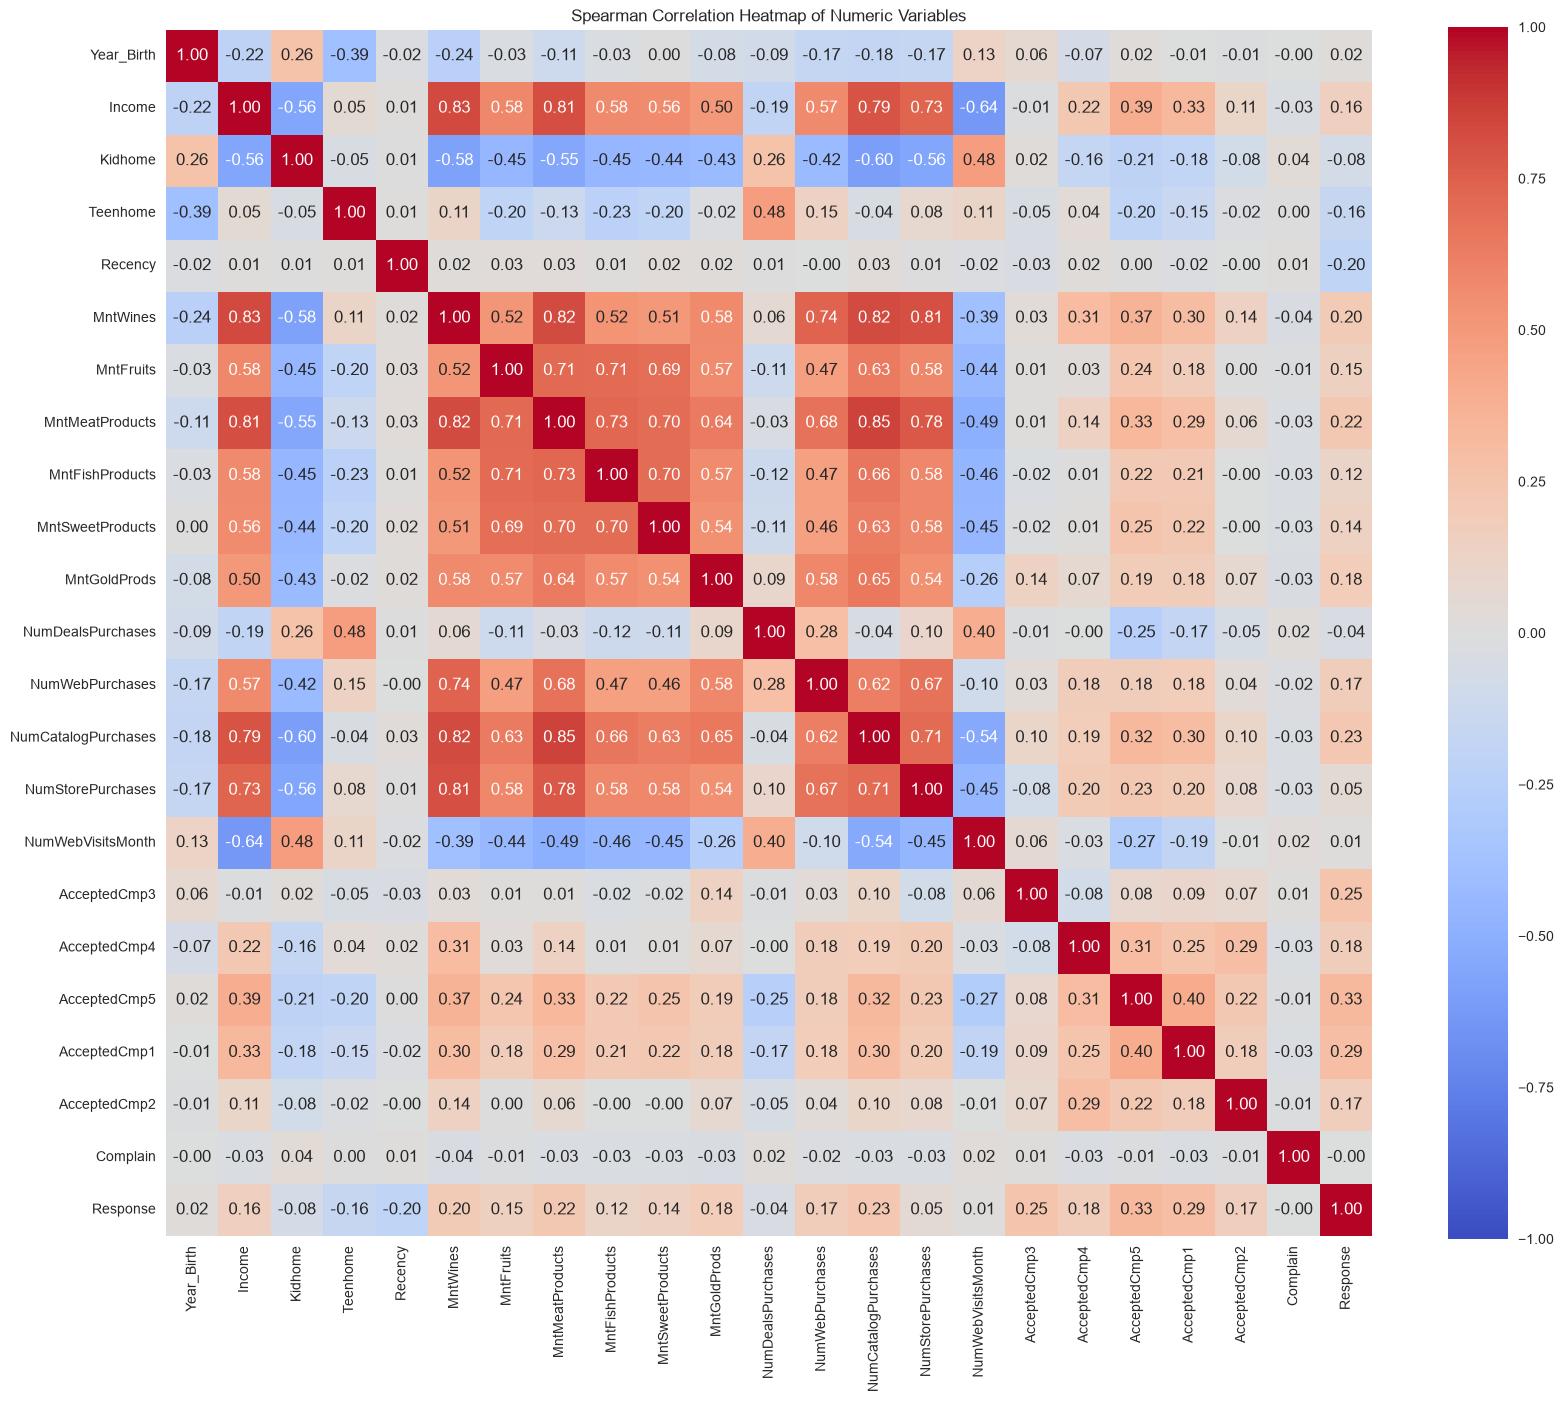

Spearman correlation
MntMeatProducts     NumCatalogPurchases              0.851660
Income              MntWines                         0.828915
MntWines            MntMeatProducts                  0.823652
                    NumCatalogPurchases              0.823421
Income              MntMeatProducts                  0.814124
MntWines            NumStorePurchases                0.806918
Income              NumCatalogPurchases              0.789215
MntMeatProducts     NumStorePurchases                0.779336
MntWines            NumWebPurchases                  0.740195
Income              NumStorePurchases                0.730125
MntMeatProducts     MntFishProducts                  0.726242
MntFruits           MntMeatProducts                  0.713169
NumCatalogPurchases NumStorePurchases                0.708612
MntFruits           MntFishProducts                  0.705016
MntFishProducts     MntSweetProducts                 0.700871
MntMeatProducts     MntSweetProducts                 0.695704
MntFruits           MntSweetProducts                 0.691356
MntMeatProducts     NumWebPurchases                  0.679243
NumWebPurchases     NumStorePurchases                0.672625
MntFishProducts     NumCatalogPurchases              0.657124

In [115]:
# Bivariate screening: correlation heatmap for numeric variables in the cleaned data.
bivariate_data = clean_data.copy()

# Omit the three unverified birth years from this analysis copy only.
bivariate_data.loc[bivariate_data["Year_Birth"] < 1920, "Year_Birth"] = np.nan

# Exclude ID (identifier); datetime and text columns are not numeric features.
numeric_features = bivariate_data.select_dtypes(include=np.number).drop(
    columns=["ID"], errors="ignore"
)
numeric_features = numeric_features.loc[:, numeric_features.nunique(dropna=True) > 1]

# Spearman correlation is suitable for these skewed variables.
spearman_corr = numeric_features.corr(method="spearman")

plt.figure(figsize=(17, 14))
sns.heatmap(
    spearman_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True
)
plt.title("Spearman Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()

# List the strongest pairs to guide the selection of follow-up plots.
upper_triangle = spearman_corr.where(
    np.triu(np.ones(spearman_corr.shape), k=1).astype(bool)
)
strongest_pairs = upper_triangle.stack().sort_values(
    key=lambda correlations: correlations.abs(), ascending=False
)
display(strongest_pairs.head(20).to_frame("Spearman correlation"))


#### Heatmap observations

The heatmap shows strong positive associations among several spending and purchase variables. The strongest is `MntMeatProducts` with `NumCatalogPurchases` (Spearman rho about 0.85). `Income` is strongly associated with `MntWines` (about 0.83) and `MntMeatProducts` (about 0.81); wine spending is also strongly associated with meat spending and catalog purchases (about 0.82).

Some relationships are negative. `Income` and `NumWebVisitsMonth` have a moderate-to-strong negative association (about -0.64). `Kidhome` is negatively associated with several spending and purchase variables (roughly -0.45 to -0.60). `Recency` has little association with most spending variables, while its association with `Response` is modestly negative (about -0.20).

These patterns suggest useful pairs for follow-up plots, especially income versus spending, spending versus purchase channels, and household size versus spending. Since strongly correlated features may represent overlapping behavior, consider that redundancy when selecting features for clustering. Correlation shows association, not cause and effect.


#### Reason for selecting these pairplot variables

The heatmap showed strong positive relationships between `Income` and product spending, and between product spending and `NumCatalogPurchases`. It also showed negative relationships between `Kidhome` and several spending/purchase variables, and between `NumWebVisitsMonth` and income/spending. The pairplot focuses on `Income`, `MntWines`, `MntMeatProducts`, `NumCatalogPurchases`, `Kidhome`, and `NumWebVisitsMonth` to inspect these strongest positive and negative patterns without plotting every numeric column. `Recency` showed little association with spending in the heatmap. Campaign indicators are binary and are better examined separately if campaign behavior is the focus; categorical variables are not included in this numeric pairplot.


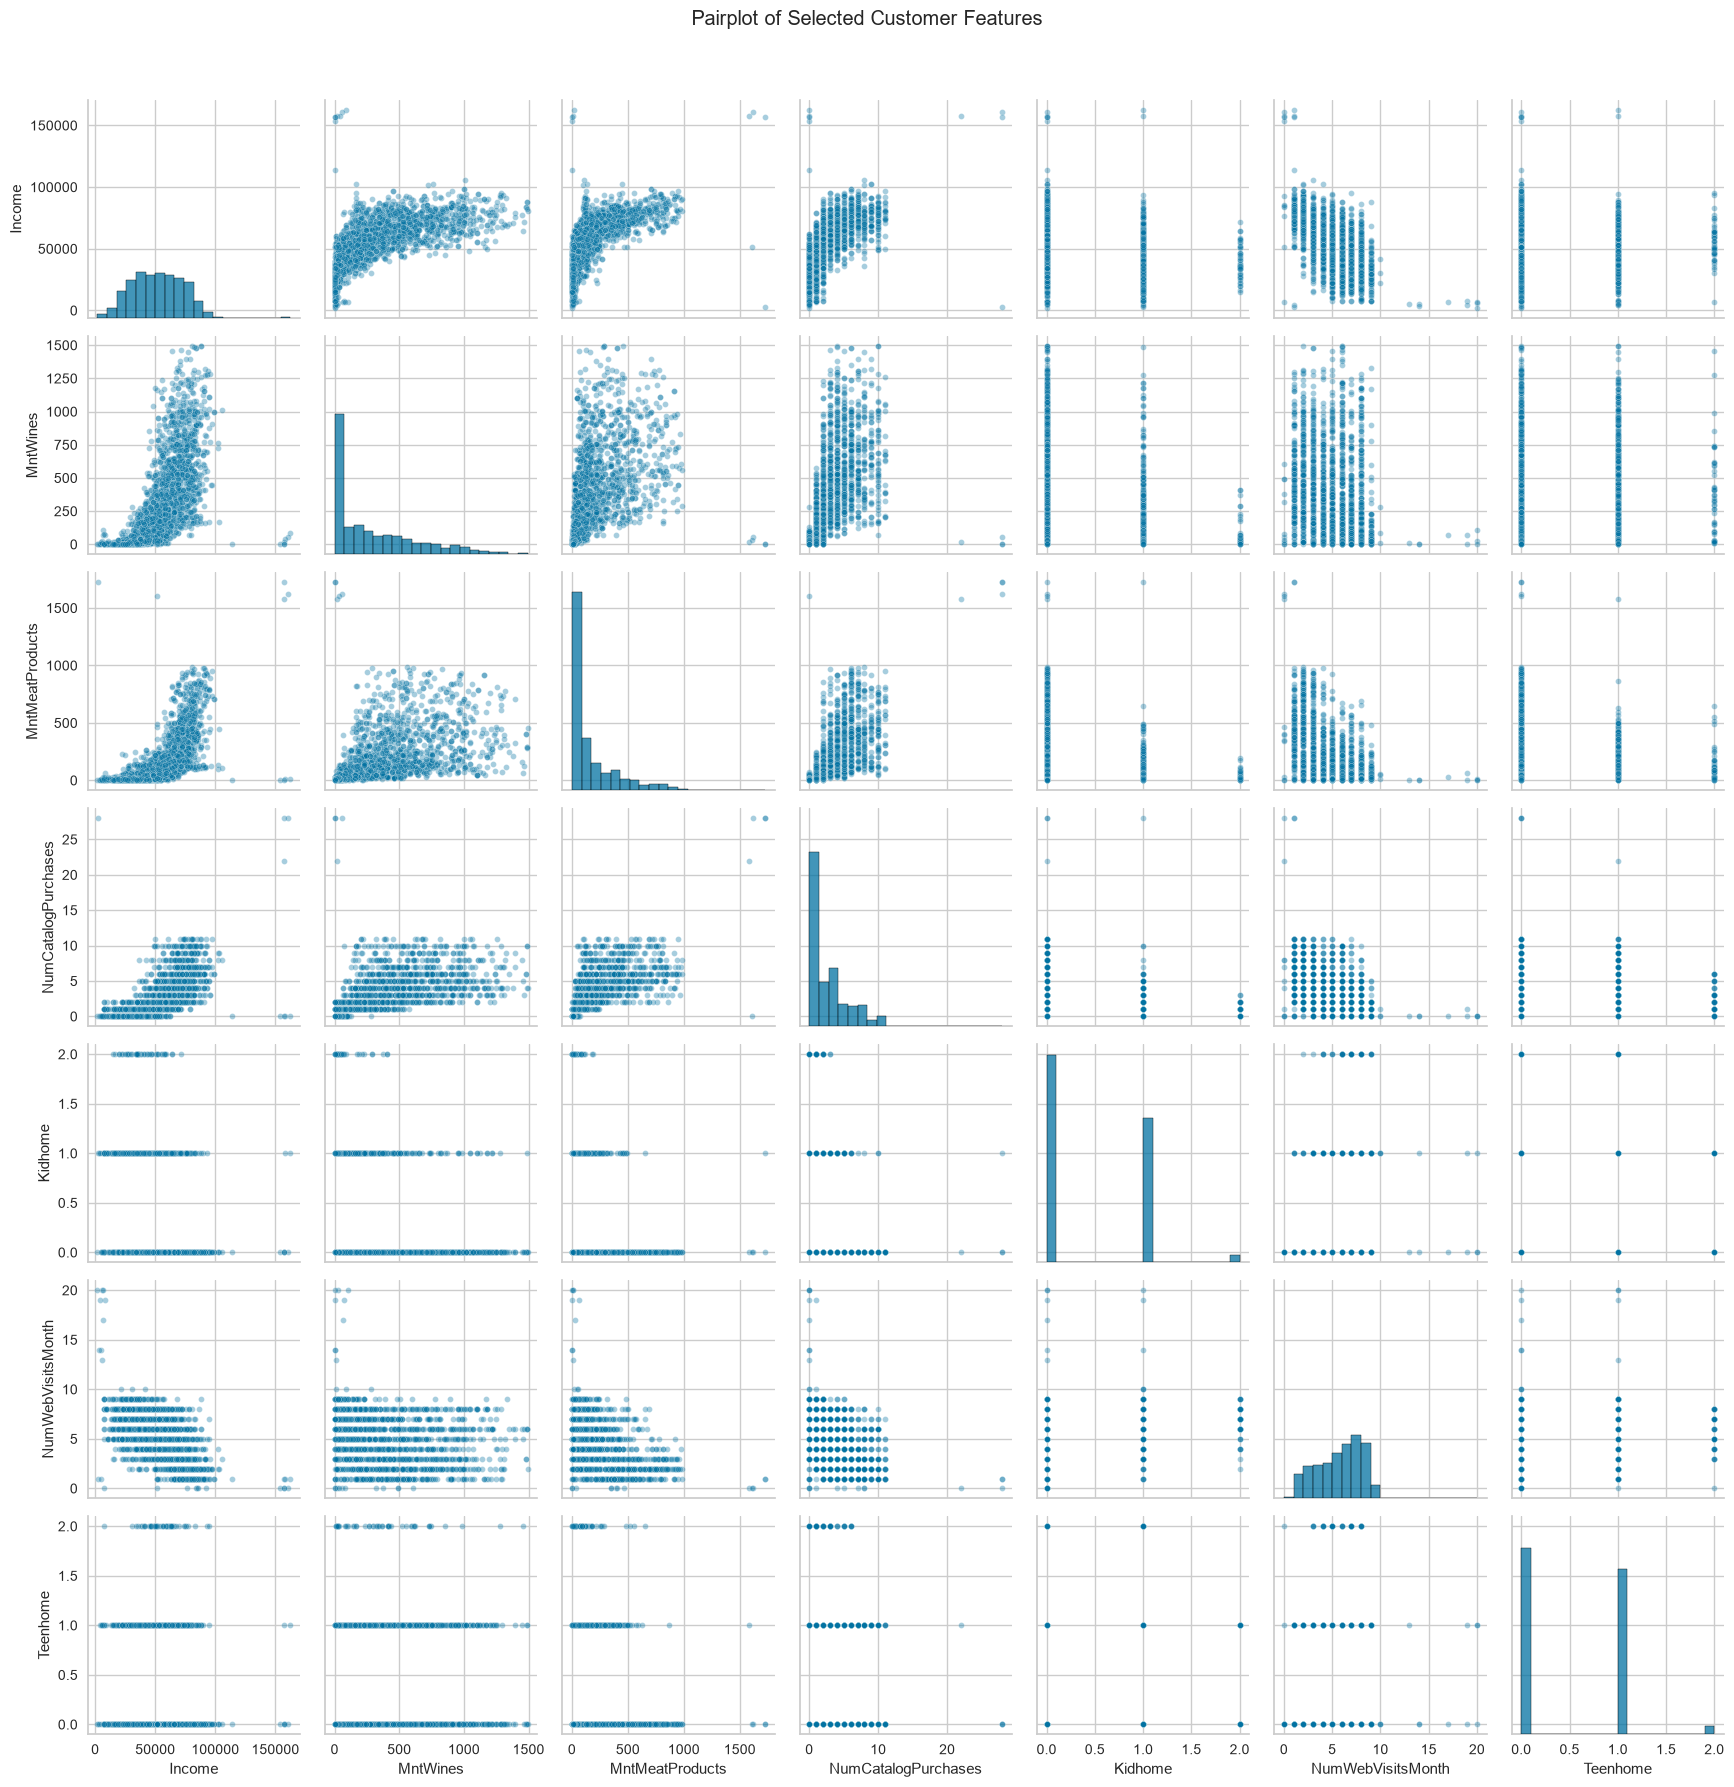

In [ ]:
# Pairplot the six features selected from the correlation heatmap.
pairplot_features = [
    "Income",
    "MntWines",
    "MntMeatProducts",
    "NumCatalogPurchases",
    "Kidhome",
    "NumWebVisitsMonth",
]

# clean_data contains the full cleaned dataset; Income is median-imputed.
pairplot_data = clean_data[pairplot_features].copy()
pair_grid = sns.pairplot(
    data=pairplot_data,
    vars=pairplot_features,
    diag_kind="hist",
    diag_kws={"bins": 20},
    plot_kws={"alpha": 0.35, "s": 18}
)
pair_grid.fig.suptitle("Pairplot of Selected Customer Features", y=1.02)
pair_grid.fig.tight_layout()
plt.show()


#### Pairplot observations

- `Income` tends to increase with `MntWines` and `MntMeatProducts`. Customers with higher incomes tends to spend more money on wine, meat product, number of catalog purchase but Customers with higher income tends to have less kids, and spend less time on  `NumWebVisitsMonth`.
- `MntWines` and `MntMeatProducts` generally rise together. `NumCatalogPurchases` also tends to be higher for customers with greater meat and wine spending.
- `Kidhome` forms discrete groups at 0, 1, and 2. Customers with more children tend overall to have lower income, lower spending and fewer catalog purchases, fewer wine and meat purchase. 

- `NumWebVisitsMonth` tends to be higher among customers with lower income and lower spending, though the scatter shows exceptions.
- The spending variables have long upper tails, so a small number of high-spending customers stretch the axes and make the main concentration of points appear compressed.



#### **Question 6:** Perform multivariate analysis to explore the relationsips between the variables.


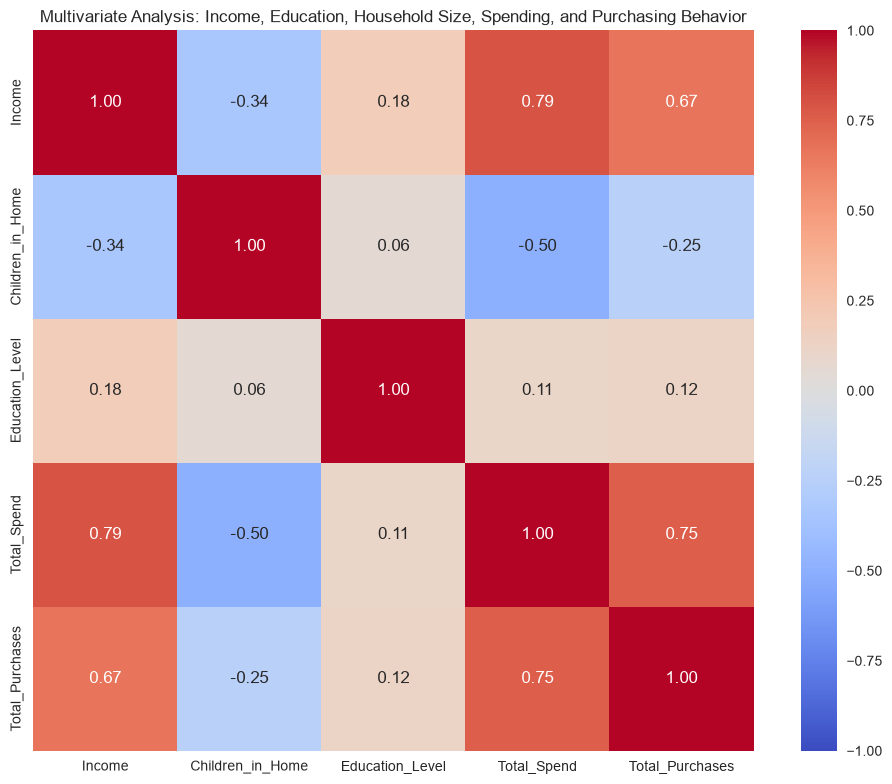

In [116]:

# Copy the cleaned dataset for multivariate analysis
multivariate_data = clean_data.copy()

# 1. Create overall spending
spending_cols = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

multivariate_data["Total_Spend"] = (
    multivariate_data[spending_cols].sum(axis=1)
)

# 2. Create overall purchasing activity
purchase_cols = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumDealsPurchases"
]

multivariate_data["Total_Purchases"] = (
    multivariate_data[purchase_cols].sum(axis=1)
)

# 3. Combine children and teenagers living at home
multivariate_data["Children_in_Home"] = (
    multivariate_data["Kidhome"] +
    multivariate_data["Teenhome"]
)

# 4. Encode education as an ordered category
education_order = [
    "Basic",
    "2n Cycle",
    "Graduation",
    "Master",
    "PhD"
]

multivariate_data["Education_Level"] = pd.Categorical(
    multivariate_data["Education"],
    categories=education_order,
    ordered=True
).codes

# Exclude any unrecognized education values encoded as -1
multivariate_data.loc[
    multivariate_data["Education_Level"] == -1,
    "Education_Level"
] = float("nan")

# 5. Select variables for the multivariate correlation heatmap
analysis_cols = [
    "Income",
    "Children_in_Home",
    "Education_Level",
    "Total_Spend",
    "Total_Purchases"
]

correlation_matrix = multivariate_data[analysis_cols].corr()

# 6. Visualize relationships between all selected variables
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title(
    "Multivariate Analysis: Income, Education, Household Size, "
    "Spending, and Purchasing Behavior"
)
plt.tight_layout()
plt.show()

### Observation

The multivariate Pearson correlation matrix shows a strong positive association between `Income` and `Total_Spend` (r = 0.79), and a positive association between `Total_Spend` and `Total_Purchases` (r = 0.75). `Income` is also positively associated with `Total_Purchases` (r = 0.67). `Children_in_Home` is negatively associated with `Total_Spend` (r = -0.50) and more weakly with `Income` (r = -0.34), so households with more children tend in this dataset to have lower spending and income. `Education_Level` has only weak positive correlations with income (r = 0.18), spending (r = 0.11), and purchases (r = 0.12).


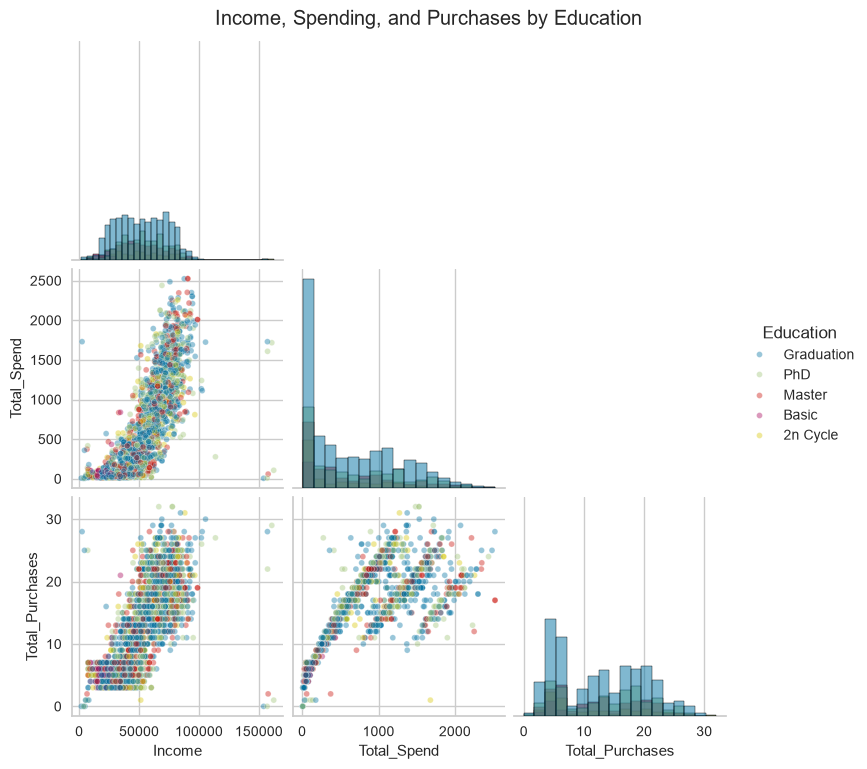

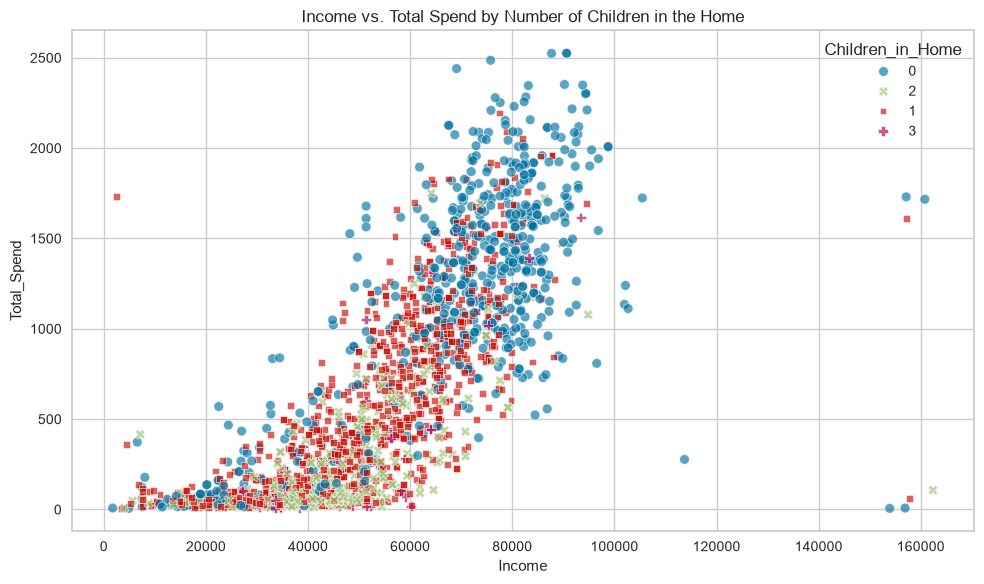

In [67]:
# Explore several variables together using the cleaned dataset.
multivariate_data = clean_data.copy()

# Derive summary measures for exploratory visualization only.
spending_cols = [
    "MntWines", "MntFruits", "MntMeatProducts",
    "MntFishProducts", "MntSweetProducts", "MntGoldProds"
]
purchase_cols = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
multivariate_data["Total_Spend"] = multivariate_data[spending_cols].sum(axis=1)
multivariate_data["Total_Purchases"] = multivariate_data[purchase_cols].sum(axis=1)
multivariate_data["Children_in_Home"] = (
    multivariate_data["Kidhome"] + multivariate_data["Teenhome"]
).astype(str)

# Compare income, spending, and purchase counts together, colored by education.
pair_grid = sns.pairplot(
    data=multivariate_data,
    vars=["Income", "Total_Spend", "Total_Purchases"],
    hue="Education",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.4, "s": 18}
)
pair_grid.fig.suptitle("Income, Spending, and Purchases by Education", y=1.02)
plt.show()

# Add household composition as a grouping variable to the income-spending relationship.
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=multivariate_data,
    x="Income",
    y="Total_Spend",
    hue="Children_in_Home",
    style="Children_in_Home",
    alpha=0.65
)
plt.title("Income vs. Total Spend by Number of Children in the Home")
plt.tight_layout()
plt.show()


##### **Observations:**

The pairplot shows that income, total spending, and total purchase count tend to increase together, with substantial overlap between education groups. Median spending is highest for PhD customers (493), followed by Graduation (414) and Master (387.5); it is lower for 2n Cycle (198) and Basic (57). These are group differences, not evidence that education causes spending differences.

The income-spending plot grouped by number of children shows lower median spending among households with more children: approximately 1,189.5 for households with no children, 305 for one, 93 for two, and 88 for three. Household income also differs across these groups, so the plots do not show that children cause lower spending. The three-child group is relatively small (53 customers), and should be interpreted cautiously.

`Income` in these plots includes median-imputed records, including the flagged value of 666,666 and original missing values. These plots are exploratory and use unscaled values; scaling and feature selection will be done later for K-means.


### Education-level comparisons: income, children, purchasing, and spending

Compare education categories using group summaries and plots. Medians and interquartile ranges help describe these distributions, which are skewed. 


,Income_count,Income_median,Income_Q1,Income_<lambda_1>,Children_in_Home_count,Children_in_Home_median,Children_in_Home_Q1,Children_in_Home_<lambda_1>,Total_Purchases_count,Total_Purchases_median,Total_Purchases_Q1,Total_Purchases_<lambda_1>,Total_Spend_count,Total_Spend_median,Total_Spend_Q1,Total_Spend_<lambda_1>
Education,,,,,,,,,,,,,,,,
Basic,54,20744.0,15405.2,24882.0,54,1.0,0.0,1.0,54,6.0,5.0,8.0,54,57.0,29.8,80.0
2n Cycle,203,46891.0,28095.0,65100.5,203,1.0,0.0,1.0,203,12.0,7.0,20.0,203,198.0,56.5,899.0
Graduation,1127,51537.0,34925.5,69673.0,1127,1.0,0.0,1.0,1127,15.0,8.0,21.0,1127,414.0,70.0,1073.0
Master,370,51044.5,37853.8,66596.0,370,1.0,0.0,1.0,370,15.0,8.0,21.0,370,387.5,79.2,988.0
PhD,486,55005.0,40654.2,69084.0,486,1.0,0.0,1.0,486,17.0,9.0,22.0,486,493.0,88.5,1157.5


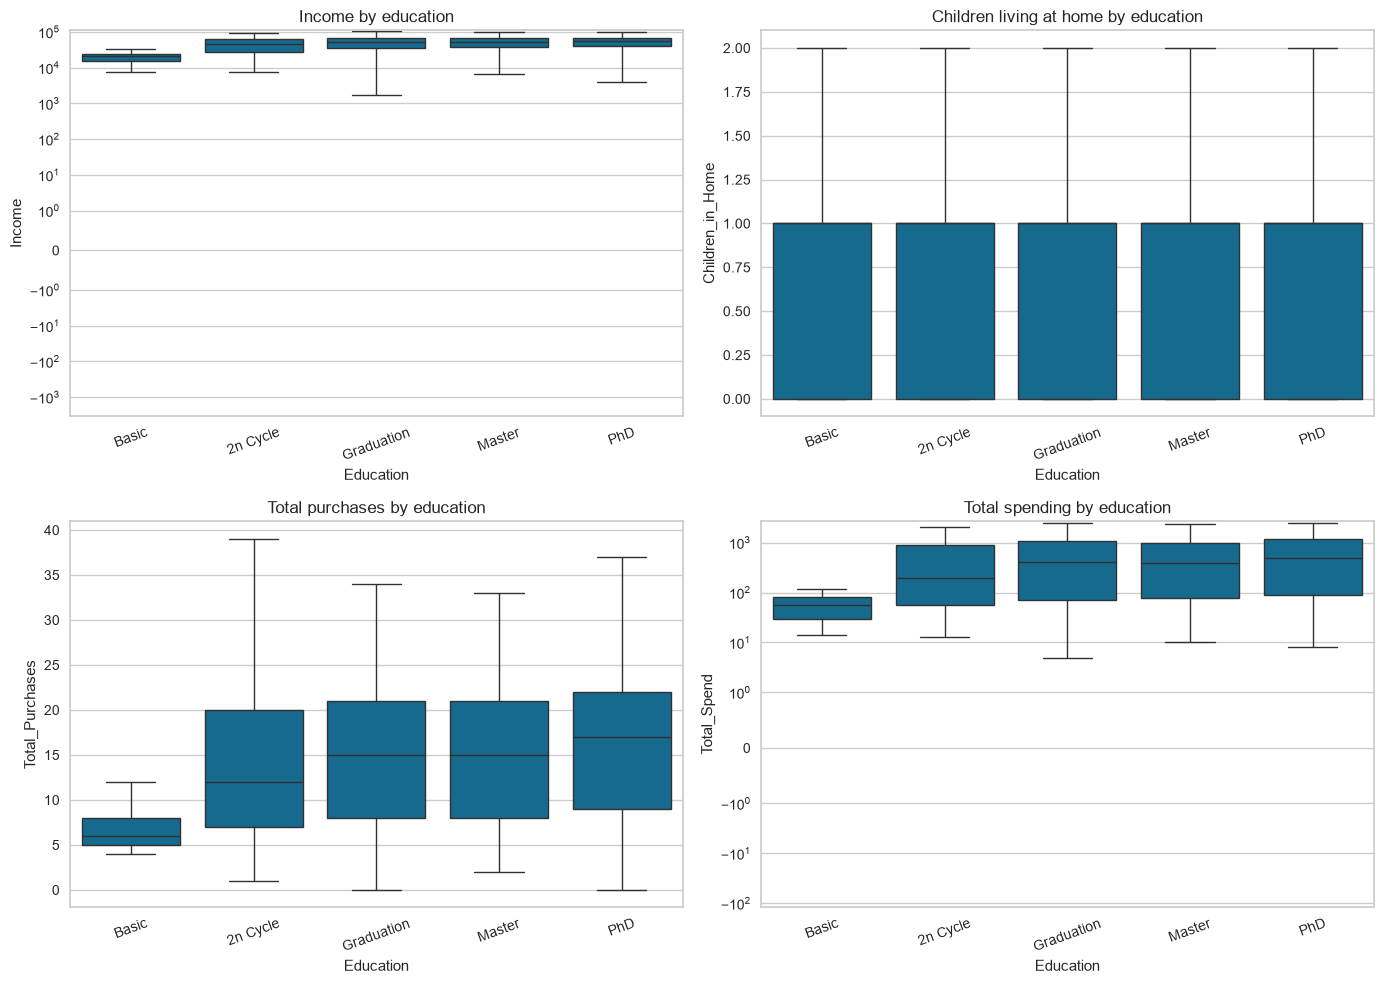

In [117]:


# Build analysis measures from the cleaned dataset.
education_analysis = clean_data.copy()
spending_cols = [
    "MntWines", "MntFruits", "MntMeatProducts",
    "MntFishProducts", "MntSweetProducts", "MntGoldProds"
]
purchase_cols = [
    "NumWebPurchases", "NumCatalogPurchases",
    "NumStorePurchases", "NumDealsPurchases"
]
education_analysis["Total_Spend"] = education_analysis[spending_cols].sum(axis=1)
education_analysis["Total_Purchases"] = education_analysis[purchase_cols].sum(axis=1)
education_analysis["Children_in_Home"] = (
    education_analysis["Kidhome"] + education_analysis["Teenhome"]
)

education_order = ["Basic", "2n Cycle", "Graduation", "Master", "PhD"]
measure_cols = ["Income", "Children_in_Home", "Total_Purchases", "Total_Spend"]

# Show group sizes, medians, and middle 50% ranges.
summary = education_analysis.groupby("Education", observed=False)[measure_cols].agg(
    ["count", "median", lambda values: values.quantile(0.25),
     lambda values: values.quantile(0.75)]
).reindex(education_order)
summary.columns = [
    f"{measure}_{stat if stat != '<lambda_0>' else 'Q1' if i % 4 == 2 else 'Q3'}"
    for measure, stat, i in [(a, b, i) for i, (a, b) in enumerate(summary.columns)]
]
display(summary.round(1))

# Compare distributions across education groups. The log scale helps show
# differences across the highly right-skewed income and spending values.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, measure, title in zip(
    axes.flat,
    ["Income", "Children_in_Home", "Total_Purchases", "Total_Spend"],
    ["Income by education", "Children living at home by education",
     "Total purchases by education", "Total spending by education"]
):
    sns.boxplot(
        data=education_analysis, x="Education", y=measure,
        order=education_order, showfliers=False, ax=ax
    )
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=20)
    if measure in ["Income", "Total_Spend"]:
        ax.set_yscale("symlog", linthresh=1)
plt.tight_layout()
plt.show()


#### Observations

The group summaries and boxplots show differences in income, spending, and purchase activity across education categories. Median income is lowest for Basic customers (20,744) and highest for PhD customers (55,005). Median total spending is lowest for Basic (57) and highest for PhD (493); median total purchases range from 6 for Basic to 17 for PhD. The distributions overlap, so education alone does not cleanly separate customers by these measures.

The median number of children living at home is one for every education group, and the boxplots show broadly similar distributions. Income comparisons include values imputed during cleaning, so interpret them with that treatment in mind. These are descriptive comparisons and do not show that education causes the observed patterns.


## **K-means Clustering**

#### **Question 7** : Select the appropriate number of clusters using the elbow Plot. What do you think is the appropriate number of clusters?

Features used for clustering:
['Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth']


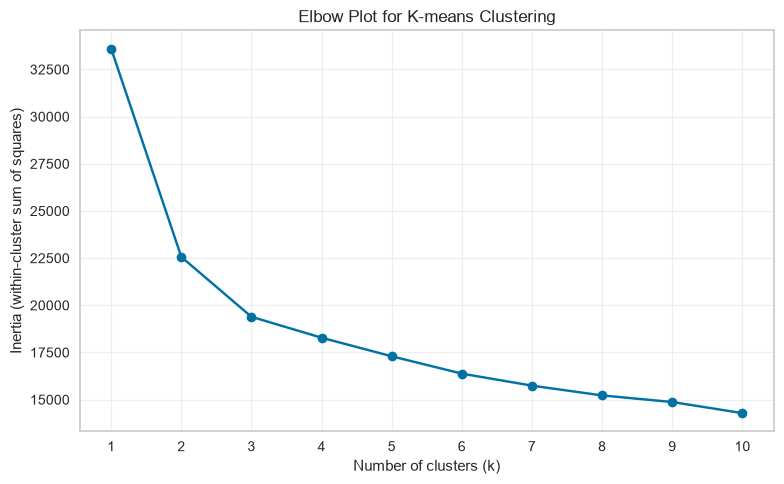

In [118]:
# Prepare numeric clustering features. ID is an identifier, so it is excluded;
# text categories and the enrollment datetime are not numeric inputs here.
# Z_CostContact and Z_Revenue are fixed values for all customers and do not give imporatant information, so they are also excluded from the clustering features.
# Response, AcceptedCmp1, AcceptedCmp2, AcceptedCmp3, AcceptedCmp4, AcceptedCmp5, and Complain are binary variables and are mostly 0s which do not have high variance, so they are not used in the clustering features, but they will be used later to evaluate the clusters.
exclude_cols = [
    "ID",
    "Response",
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Complain",
    "Z_CostContact",
    "Z_Revenue",
    "Year_Birth"
]

clustering_data = clean_data.copy()

# Select variable numeric features, excluding the listed columns.
clustering_features = clustering_data.select_dtypes(
    include=np.number
).drop(columns=exclude_cols, errors="ignore")

clustering_features = clustering_features.loc[
    :, clustering_features.nunique(dropna=True) > 1
]

print("Features used for clustering:")
print(clustering_features.columns.tolist())

# Standardize because K-means uses distances and the variables have different scales.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(clustering_features)

# Fit K-means for a range of k values and record within-cluster sum of squares.
k_values = range(1, 11)
inertias = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.title("Elbow Plot for K-means Clustering")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


##### **Observations:**

The elbow plot shows a large decrease in inertia from 1 to 2 clusters, followed by smaller, more gradual improvements as additional clusters are added. This makes **k = 2** a reasonable provisional choice from the elbow method. The bend is not perfectly sharp, so the plot alone does not establish a definitive answer; we will compare this choice with the silhouette scores in Question 8.


,Number of clusters (k),Average silhouette score
0,2,0.3232
1,3,0.2559
2,4,0.1652
3,5,0.1552
4,6,0.1594
5,7,0.1518
6,8,0.1535
7,9,0.1499
8,10,0.1471


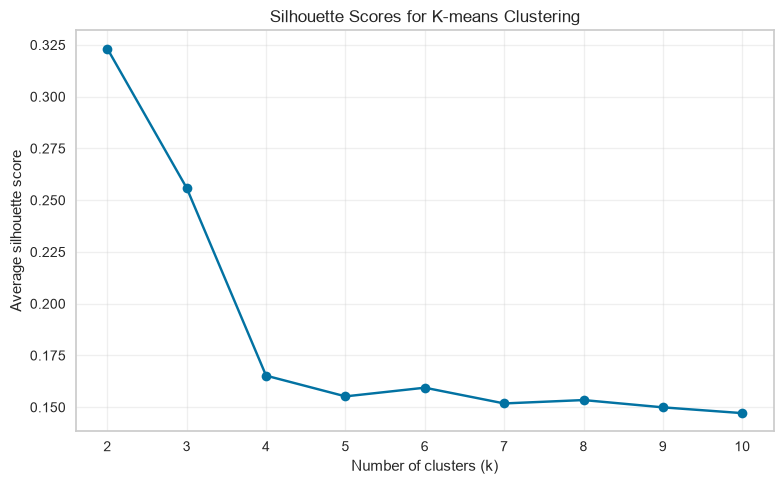

Highest silhouette score is for k = 2.


In [119]:
# Compare average silhouette scores for candidate cluster counts.
# k must be at least 2 for the silhouette score to be defined.
from sklearn.metrics import silhouette_score

silhouette_k_values = range(2, 11)
silhouette_scores = []
for k in silhouette_k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

silhouette_results = pd.DataFrame({
    "Number of clusters (k)": list(silhouette_k_values),
    "Average silhouette score": silhouette_scores
})
display(silhouette_results.round(4))

plt.figure(figsize=(8, 5))
plt.plot(
    silhouette_results["Number of clusters (k)"],
    silhouette_results["Average silhouette score"],
    marker="o"
)
plt.xticks(list(silhouette_k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("Average silhouette score")
plt.title("Silhouette Scores for K-means Clustering")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


best_k_silhouette = int(
    silhouette_results.loc[
        silhouette_results["Average silhouette score"].idxmax(),
        "Number of clusters (k)"
    ]
)
print(f"Highest silhouette score is for k = {best_k_silhouette}.")


##### **Observations:**

The highest average silhouette score is for **k = 2** (about 0.32), so the silhouette analysis agrees with the elbow plot. The score is positive but modest, which suggests the two groups are not sharply separated and some customers overlap. We will use **2 clusters** for the final fit, while treating the resulting segments as broad patterns rather than clearly distinct customer types.


#### **Question 9**: Do a final fit with the appropriate number of clusters. How much total time does it take for the model to fit the data?

In [120]:
import time

# Final K-means fit using the number of clusters selected in Questions 7 and 8.
final_k = 2
kmeans_final = KMeans(n_clusters=final_k, random_state=42, n_init=10)

start_time = time.perf_counter()
kmeans_final.fit(X_scaled)
fit_time_seconds = time.perf_counter() - start_time

# Keep the fitted cluster assignment with each customer's original cleaned record.
clustered_data = clean_data.copy()
clustered_data["Cluster"] = kmeans_final.labels_

print(f"Number of clusters: {final_k}")
print(f"Model fit time: {fit_time_seconds:.4f} seconds")
print("Customers in each cluster:")
print(clustered_data["Cluster"].value_counts().sort_index())


Number of clusters: 2
Model fit time: 0.0328 seconds
Customers in each cluster:
Cluster
0     922
1    1318
Name: count, dtype: int64


##### **Observations:**

##### Observations

The final K-means model was fitted with **2 clusters**, using the standardized numerical features prepared above. The measured model fitting time was approximately 0.0328 seconds. The model assigned 922 customers to Cluster 0 and 1,318 customers to Cluster 1.

These results describe the final model fit. The fitting time measures the execution of `kmeans_final.fit(X_scaled)`, not the time required for the entire data preparation and clustering pipeline.


## **Cluster Profiling and Comparison**

#### **Question 10**: Perform cluster profiling using boxplots for the K-Means algorithm. Analyze key characteristics of each cluster and provide detailed observations.

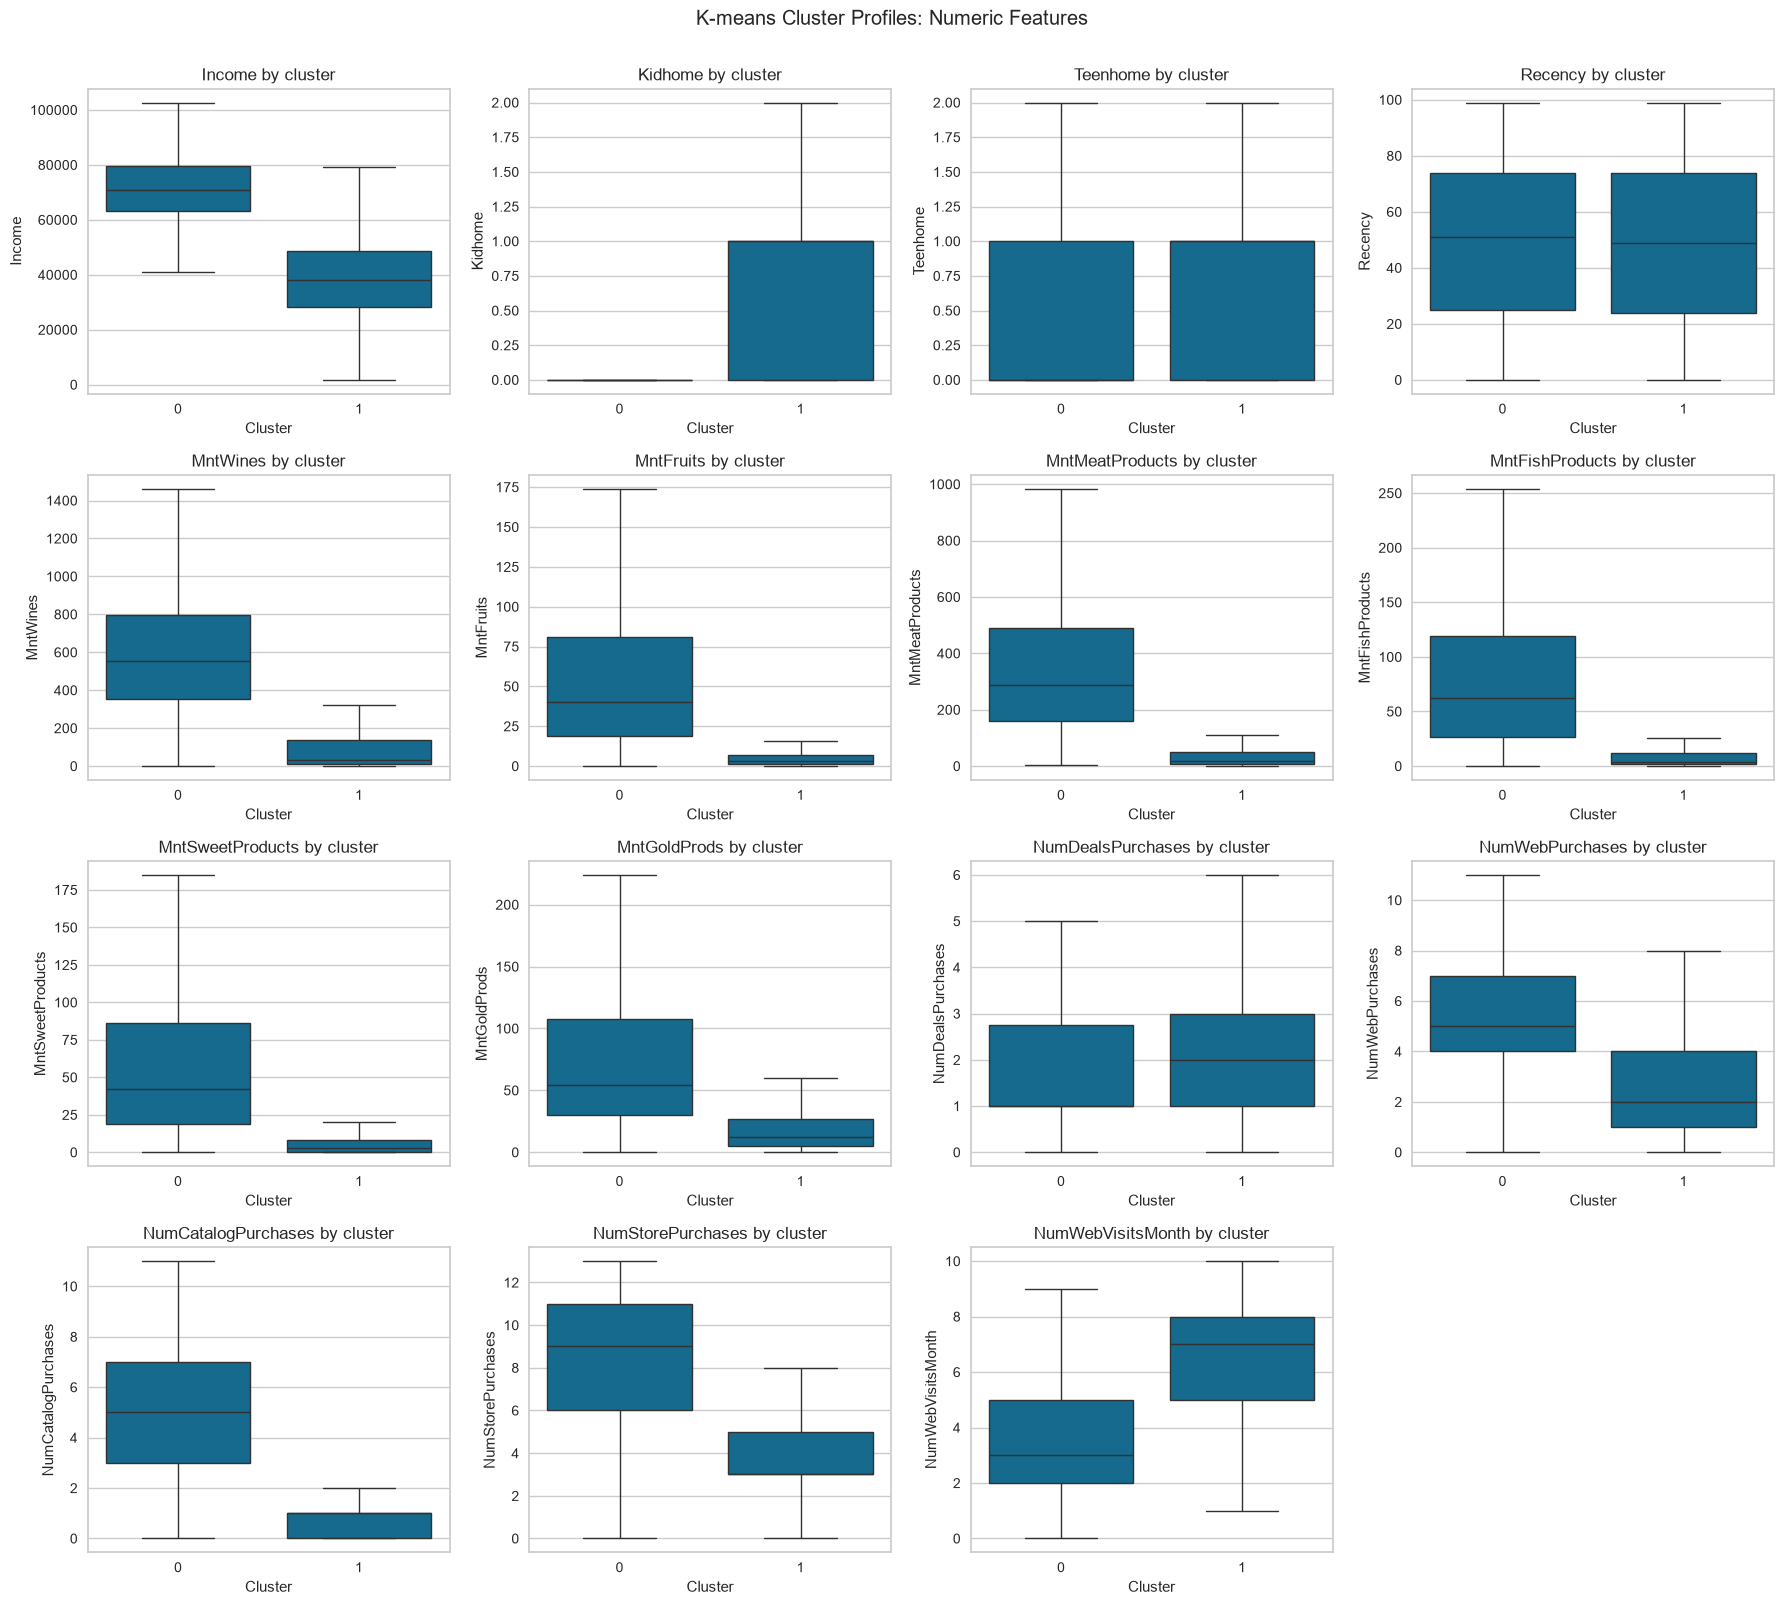

,Customers,Income_median,Total_Spend_median,Total_Purchases_median,Children_in_Home_median,Recency_median,Web_Visits_median,Response_rate
Cluster,,,,,,,,
0,922,70928.0,1156.5,21.0,0.0,51.0,3.0,21.9
1,1318,38234.0,87.5,9.0,1.0,49.0,7.0,10.0


Customers accepting at least one campaign (%):


Cluster
0    33.9
1    11.4
Name: Campaign_acceptance_rate, dtype: float64

In [121]:
# Add interpretable summary measures for profiling and later comparisons.
clustered_data["Total_Spend"] = clustered_data[
    ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts",
     "MntSweetProducts", "MntGoldProds"]
].sum(axis=1)
clustered_data["Total_Purchases"] = clustered_data[
    ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases",
     "NumDealsPurchases"]
].sum(axis=1)
clustered_data["Children_in_Home"] = (
    clustered_data["Kidhome"] + clustered_data["Teenhome"]
)

# Compare the distributions of every numeric clustering feature across clusters.
profile_features = clustering_features.columns.tolist()
n_cols = 4
n_rows = int(np.ceil(len(profile_features) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, feature in zip(axes, profile_features):
    sns.boxplot(
        data=clustered_data,
        x="Cluster",
        y=feature,
        order=[0, 1],
        showfliers=False,
        ax=ax
    )
    ax.set_title(f"{feature} by cluster")
    ax.set_xlabel("Cluster")

# Hide any unused panels in the final row.
for ax in axes[len(profile_features):]:
    ax.set_visible(False)

fig.suptitle("K-means Cluster Profiles: Numeric Features", y=1.002)
plt.tight_layout()
plt.show()

# Summarize central values and cluster sizes for key business measures.
profile_summary = clustered_data.groupby("Cluster").agg(
    Customers=("Cluster", "size"),
    Income_median=("Income", "median"),
    Total_Spend_median=("Total_Spend", "median"),
    Total_Purchases_median=("Total_Purchases", "median"),
    Children_in_Home_median=("Children_in_Home", "median"),
    Recency_median=("Recency", "median"),
    Web_Visits_median=("NumWebVisitsMonth", "median"),
    Response_rate=("Response", "mean")
)
profile_summary["Response_rate"] *= 100
display(profile_summary.round(1))

# Campaign acceptance rate: customer accepted at least one of the five campaigns.
campaign_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"]
campaign_acceptance = clustered_data[campaign_cols].max(axis=1).groupby(clustered_data["Cluster"]).mean() * 100
print("Customers accepting at least one campaign (%):")
display(campaign_acceptance.round(1).rename("Campaign_acceptance_rate"))


##### **Observations:**

The boxplots and profile summary show two distinct broad customer profiles. **Cluster 0** contains 922 customers (about 41%) and has higher medians for income (70,928), total spending (1,156.5), and total purchases (21). Its median number of children at home is 0. **Cluster 1** contains 1,318 customers (about 59%) and has lower medians for income (38,234), total spending (87.5), and total purchases (9), with a median of 1 child at home. Cluster 1 visits the website more often at the median (7 times per month, compared with 3 for Cluster 0), despite lower median purchasing and spending.

Median recency is similar: 51 days for Cluster 0 and 49 for Cluster 1. The latest campaign response rate is about 21.9% in Cluster 0 and 10.0% in Cluster 1; 33.9% of Cluster 0 and 11.4% of Cluster 1 accepted at least one of the five previous campaigns. These campaign measures were not used to form the clusters, so they provide additional descriptive comparisons. Cluster labels are arbitrary. The boxplots hide individual fliers to make the central distributions easier to compare; no customers were removed from the analysis.


#### **Question 11**: Perform cluster profiling on the data using a barplot for the K-Means algorithm. Provide insights and key observations for each cluster based on the visual analysis.

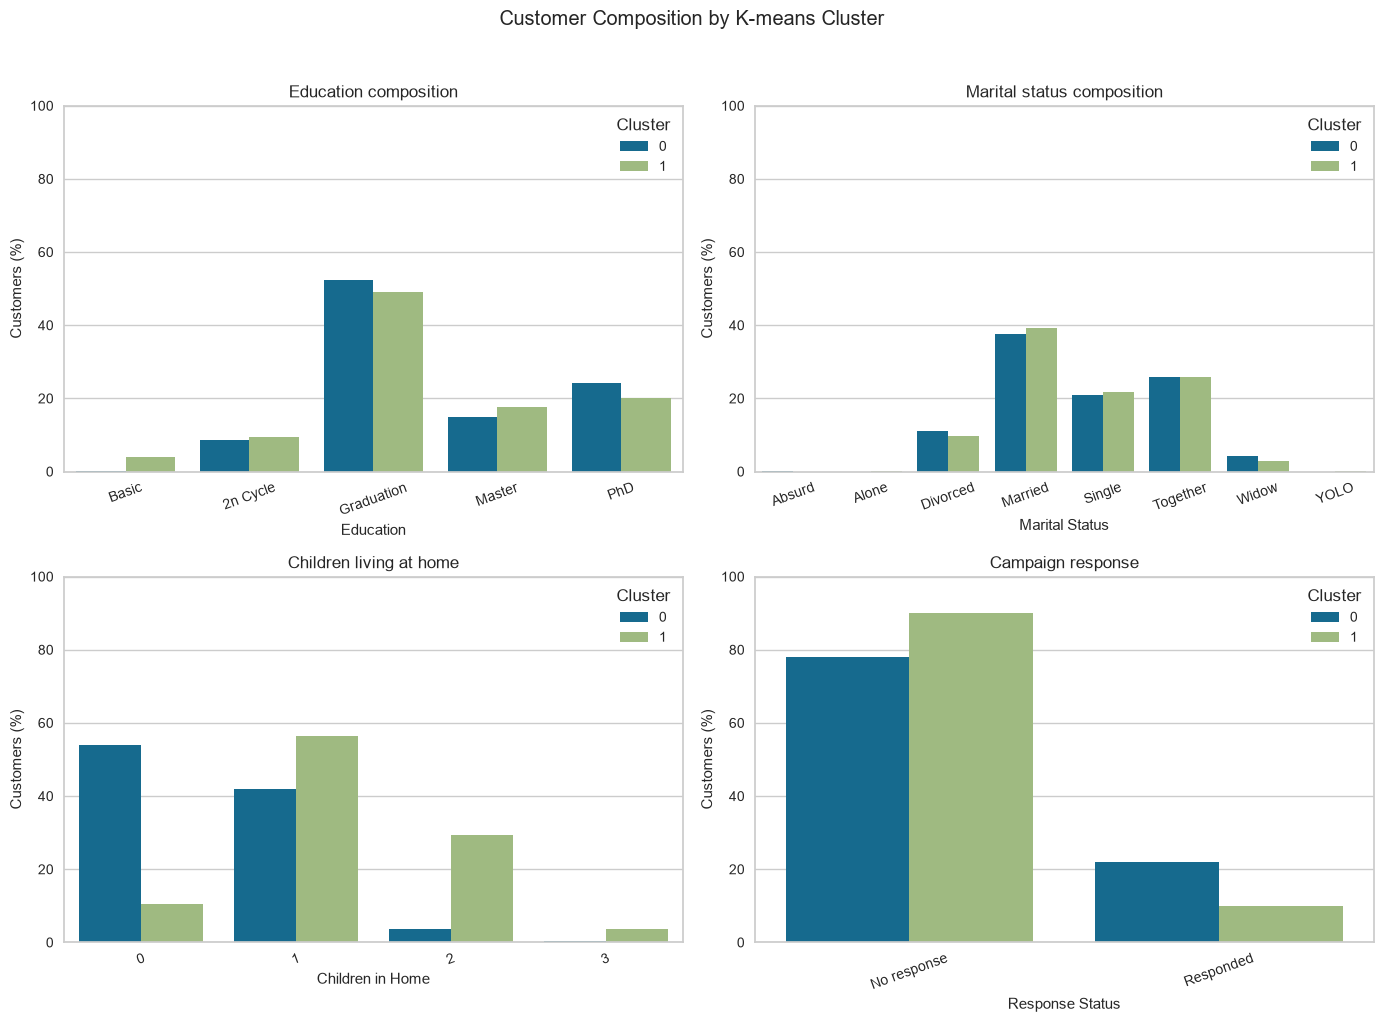

In [122]:
# Compare cluster composition using within-cluster percentages so the
# different cluster sizes do not dominate the categorical comparisons.
barplot_data = clustered_data.copy()
barplot_data["Children_in_Home"] = barplot_data["Children_in_Home"].astype(str)
barplot_data["Response_Status"] = barplot_data["Response"].map(
    {0: "No response", 1: "Responded"}
)

category_specs = [
    ("Education", ["Basic", "2n Cycle", "Graduation", "Master", "PhD"],
     "Education composition"),
    ("Marital_Status", None, "Marital status composition"),
    ("Children_in_Home", ["0", "1", "2", "3"],
     "Children living at home"),
    ("Response_Status", ["No response", "Responded"],
     "Campaign response")
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (feature, category_order, title) in zip(axes.flat, category_specs):
    proportions = pd.crosstab(
        barplot_data["Cluster"], barplot_data[feature], normalize="index"
    ).mul(100)
    proportions = proportions.reindex(columns=category_order, fill_value=0) if category_order else proportions
    proportions = proportions.rename_axis("Cluster").reset_index().melt(
        id_vars="Cluster", var_name=feature, value_name="Customers (%)"
    )
    sns.barplot(
        data=proportions,
        x=feature,
        y="Customers (%)",
        hue="Cluster",
        hue_order=[0, 1],
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel(feature.replace("_", " "))
    ax.tick_params(axis="x", rotation=20)
    ax.set_ylim(0, 100)
    ax.legend(title="Cluster")

fig.suptitle("Customer Composition by K-means Cluster", y=1.02)
plt.tight_layout()
plt.show()


##### **Observations:**

The proportion barplots show the clearest categorical difference in household composition. About 54% of Cluster 0 have no children at home, compared with 11% of Cluster 1. One child is the most common category in Cluster 1 (56%); about 29% have two children, compared with 4% of Cluster 0. The latest campaign response rate is also higher in Cluster 0 (21.9%) than Cluster 1 (10.0%).

Education and marital-status distributions are broadly similar between the clusters. Graduation is the most common education category in both (52% of Cluster 0 and 49% of Cluster 1); Married and Together are the most common marital statuses in both. Basic education is more common in Cluster 1 (4%) than Cluster 0 (less than 1%), but remains a small share overall. The bars show percentages within each cluster, accounting for their different sizes.


## **Business Recommedations**

#### **Question 12**: Based on the cluster insights, what business recommendations can be provided?

##### **Business Recommendations:**

- **Cluster 0 : higher spending and purchase activity:** Focus on retention with loyalty benefits, early access, complementary product recommendations, and convenient repeat-purchase options. Their stronger historical campaign response suggests they may be receptive to relevant campaigns; prioritize useful offers over unnecessary discounts to protect margin.
- **Cluster 1 : lower spending, more children at home, and more web visits:** Test family-oriented bundles, affordable product combinations, and clear value offers. Since this group visits the website more often but purchases less, review the online journey and test targeted product suggestions or checkout improvements to see whether they increase conversion.
- **Measure results before scaling:** Run small controlled campaign tests and compare conversion, revenue, and profit against a control group. The clusters overlap and the silhouette score is modest, so use these segments as an initial guide rather than fixed customer labels.
- **Use the segments responsibly:** Avoid treating income or family composition as a proxy for an individual customer's needs. Personalize based on observed preferences and allow campaign performance and customer feedback to guide decisions.

